#  TALLER PRÁCTICO 01 — Aprendizaje Automático con Big Data
## Predicción del Precio de Viviendas en Inglaterra y Gales

**Estudiante:** Jose Alejandro Bernal Figueroa  

**Entorno:** Google Colab

**Metodología:** CRISP-DM  
**Técnica:** Regresión Lineal (OLS, Ridge, Lasso, ElasticNet y A criterio mio despues de las pruebas con la regresion Lineal decidi probar con modelos como Random Forest y Hist Gradient Boosting con Transformación Logaritmica)  
**Dataset:** *Residential property transactions and EPC for England and Wales, 2011–2019*  
**Registros:** +5.7 millones de transacciones · 105 columnas  
**Muestra de trabajo:** 650,000 filas (muestreo aleatorio )  

---


---
#  Fase 1 — Comprensión del Negocio
---

## 1.1 Contexto del Problema

El mercado inmobiliario de Inglaterra y Gales representa una de las mayores concentraciones de riqueza del Reino Unido. Nuestro primer objetivo es entender que variables y factores determinan el precio de una propiedad:

| Stakeholder | Necesidad |
|---|---|
| **Compradores / Vendedores** | Estimar si un precio de oferta es justo |
| **Agentes inmobiliarios** | Tasación automatizada para fijar precios de lista |
| **Bancos / Hipotecarios** | Valoración de colateral para aprobación de créditos |
| **Gobiernos locales** | Planificación urbana y análisis de accesibilidad |
| **Investigadores** | Estudio de dinámicas de precio por metro cuadrado |

### Fuente de datos

El dataset combina dos fuentes oficiales abiertas:

1. **Land Registry Price Paid Data (PPD):** Registro exhaustivo de transacciones residenciales de mercado abierto (precio pagado, fecha, tipo de propiedad, tenencia).
2. **Domestic Energy Performance Certificates (EPC):** Certificados de eficiencia energética que incluyen área total, número de habitaciones, calificación energética, costos estimados de calefacción/iluminación/agua caliente, emisiones de CO₂, y descripciones de elementos constructivos.

### Al buscar informacion del dataset miramos que
Ambos conjuntos fueron enlazados mediante un proceso de cuatro etapas de emparejamiento por dirección postal (Chi et al., 2024), generando **5,732,838 registros** con 105 variables.

### Limitaciones conocidas

- **Sesgo temporal:** Los datos cubren 2011–2019. No reflejan el impacto posterior.
- **Sesgo de cobertura:** Solo el 79 % de las transacciones PPD pudo ser enlazado con un EPC. Propiedades sin certificado energético están excluidas.
- **Variables omitidas:** No se dispone de variables como estado de remodelación, proximidad a transporte público, calidad del vecindario, vistas, o condición interior de la propiedad.
- **EPC estático:** El certificado refleja la condición de la propiedad en la fecha de evaluación, que puede no coincidir con la fecha de venta.
- **Sin direcciones:** Por restricciones de licencia, las direcciones y códigos postales completos fueron removidos del dataset enlazado.


## 1.2 Objetivo de Negocio

> **El objetivo del trabajo sera entonces construir un modelo de regresión lineal que prediga el precio de venta (`pricepaid`) de una propiedad residencial en Inglaterra y Gales, utilizando características físicas de la vivienda, calificaciones de eficiencia energética e indicadores geográficos, de modo que el error medio de predicción sea interpretable y útil para una primera estimación de un valor real.**

### Criterio de éxito

- **Métrica principal:** MAE (Mean Absolute Error) — indica en libras esterlinas cuánto se desvía la predicción en promedio.
- **Métricas complementarias:** RMSE (sensible a errores grandes), MAPE (error porcentual), R² (varianza explicada).
- El trabajo nos dice que un modelo con un MAE inferior a £50,000 y un R² superior a 0.40 se consideraría un resultado competente para un modelo lineal baseline sobre datos de esta naturaleza.

---
#  Fase 2 — Comprensión de los Datos y Análisis Exploratorio (EDA)
---

## 2.1 Configuración del Entorno e Instalación de Dependencias

In [ ]:
# ============================================================================
# Instalación / importación de librerías
# ============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)

# Configuración visual
sns.set_theme(style='whitegrid', palette='viridis', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(' Librerías importadas correctamente.')

 Librerías importadas correctamente.


## 2.2 Conexión a Google Drive

Dado que el archivo CSV es pesado lo leeremos directamente desde drive sin descargarlo en la sesión.

In [ ]:
# ============================================================================
# Conectar a Google Drive
# ============================================================================
from google.colab import drive
import os

# Montar Google Drive
drive.mount('/content/drive')

# ============================================================================
# Enlazar ruta
# ============================================================================
CSV_FILE = '/content/drive/MyDrive/Lab1/tranall2011_19.csv'

if os.path.exists(CSV_FILE):
    print(f'\n[OK] Archivo encontrado en: {CSV_FILE}')
    size_gb = os.path.getsize(CSV_FILE) / (1024**3)
    print(f'Tamano del CSV: {size_gb:.2f} GB')
else:
    print(f'\n[ERROR] Archivo no encontrado en: {CSV_FILE}')
    print('Por favor, ajusta la variable CSV_FILE con la ruta correcta a tu archivo.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[OK] Archivo encontrado en: /content/drive/MyDrive/Lab1/tranall2011_19.csv
Tamano del CSV: 5.87 GB


## 2.3 Carga Eficiente en Memoria: Muestra Aleatoria de 650,000 Filas

###  Restricción de RAM

Google Colab dispone de 12 GB de RAM. El CSV completo puede superar los 10 GB en memoria. Por tanto, **no se carga el archivo completo**.

### Estrategia de muestreo

1. Se cuenta el número total de líneas del archivo (sin cargarlo en memoria).
2. Se genera un conjunto aleatorio de índices de fila a **saltar** (`skiprows`).
3. Se pasa ese conjunto a `pd.read_csv()`, de modo que solo se leen ~650,000 filas.

Esta es una buena técnica porque `skiprows` con un `set` es rápida en pandas y evita cargar el archivo completo.

In [ ]:
# ============================================================================
# Carga eficiente: muestra aleatoria de 650,000 filas
# ============================================================================
SAMPLE_SIZE = 650_000

# Paso 1: Contar líneas del archivo sin cargarlo en memoria
print('Contando el número total de filas del archivo...')
with open(CSV_FILE, 'r', encoding='utf-8', errors='replace') as f:
    total_lines = sum(1 for _ in f)

total_rows = total_lines - 1  # Restamos la línea de encabezado
print(f'   Total de filas (sin encabezado): {total_rows:,}')

# Paso 2: Generar índices aleatorios a MANTENER (protección si es archivo pequeño)
actual_sample_size = min(SAMPLE_SIZE, total_rows)
np.random.seed(RANDOM_STATE)
rows_to_keep = set(np.random.choice(range(1, total_lines), size=actual_sample_size, replace=False))

# Paso 3: Definir función skiprows — saltar las filas que NO están en la muestra
# La fila 0 es el header, nunca se salta
skip_func = lambda i: i != 0 and i not in rows_to_keep

# Paso 4: Cargar con read_csv usando skiprows
print(f'Cargando muestra aleatoria de {actual_sample_size:,} filas...')
df = pd.read_csv(
    CSV_FILE,
    skiprows=skip_func,
    low_memory=False,
    encoding='utf-8',
    on_bad_lines='skip'
)

# Normalizar nombres de columnas (todo a minúsculas y sin espacios extras)
df.columns = df.columns.str.strip().str.lower()

# Eliminar columnas duplicadas (el CSV tiene 'county' dos veces: transaccion y EPC)
dupes = df.columns[df.columns.duplicated()].tolist()
if dupes:
    print(f'[WARN] Columnas duplicadas detectadas: {dupes}. Se conserva la primera aparicion.')
    df = df.loc[:, ~df.columns.duplicated()]

print(f'[OK] Muestra cargada: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Uso de memoria: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print('Nombres de columnas normalizados a minúsculas para evitar errores (KeyError).')


Contando el número total de filas del archivo...
   Total de filas (sin encabezado): 5,732,838
Cargando muestra aleatoria de 650,000 filas...
[WARN] Columnas duplicadas detectadas: ['county']. Se conserva la primera aparicion.
[OK] Muestra cargada: 650,000 filas x 104 columnas
Uso de memoria: 2778.9 MB
Nombres de columnas normalizados a minúsculas para evitar errores (KeyError).


## 2.4 Reconocimiento General del Dataset

In [ ]:
# ============================================================================
# Reconocimiento general
# ============================================================================
print('=' * 70)
print('DIMENSIONES')
print('=' * 70)
print(f'Filas:    {df.shape[0]:,}')
print(f'Columnas: {df.shape[1]}')
print()

print('=' * 70)
print('TIPOS DE DATOS')
print('=' * 70)
print(df.dtypes.value_counts())
print()

print('=' * 70)
print('PRIMERAS 5 FILAS')
print('=' * 70)
df.head()

DIMENSIONES
Filas:    650,000
Columnas: 104

TIPOS DE DATOS
object     68
int64      20
float64    16
Name: count, dtype: int64

PRIMERAS 5 FILAS


,id,transactionid,oa11,postcode,price,dateoftransfer,propertytype,oldnew,duration,paon,...,main_fuel,wind_turbine_count,heat_loss_corridoor,unheated_corridor_length,floor_height,photo_supply,solar_water_heating_flag,mechanical_ventilation,local_authority_label,constituency_label
0,10000014,{DF7FF768-C49A-46D2-AC47-EF0F96799040},E00155731,RH4 1HH,138000.0,2014-06-19,F,N,L,36,...,electricity (not community),0,heated corridor,NaN,2.38,0.0,NaN,natural,Mole Valley,Mole Valley
1,10000029,{797D6CCC-2E3E-4FA4-B1AA-3172446F3E70},E00155839,RH5 6JF,835000.0,2015-07-17,D,N,F,FERN BANK,...,oil (not community),0,NO DATA!,NaN,NaN,NaN,N,natural,Mole Valley,Mole Valley
2,10000029,{E11E3BE9-E337-478C-8F00-F6A92FFA1718},E00155839,RH5 6JF,250000.0,2013-10-22,D,N,F,FERN BANK,...,oil (not community),0,NO DATA!,NaN,NaN,NaN,N,natural,Mole Valley,Mole Valley
3,10000066,{2FD36066-098A-4BF8-E050-A8C0620562B1},E00155766,KT22 9HD,858500.0,2016-02-16,D,N,F,59,...,mains gas (not community),0,NO DATA!,NaN,NaN,NaN,N,natural,Mole Valley,Mole Valley
4,10000120,{582D0637-8B8B-8F22-E053-6C04A8C01BAC},E00155602,KT21 2JQ,510000.0,2017-07-19,S,N,F,30,...,mains gas (not community),0,NO DATA!,NaN,NaN,NaN,N,natural,Mole Valley,Epsom and Ewell


In [ ]:
# ============================================================================
# Lista completa de columnas
# ============================================================================
print('LISTA COMPLETA DE COLUMNAS:')
print('-' * 40)
for i, col in enumerate(df.columns, 1):
    print(f'{i:3d}. {col}')

LISTA COMPLETA DE COLUMNAS:
----------------------------------------
  1. id
  2. transactionid
  3. oa11
  4. postcode
  5. price
  6. dateoftransfer
  7. propertytype
  8. oldnew
  9. duration
 10. paon
 11. saon
 12. street
 13. locality
 14. towncity
 15. district
 16. county
 17. categorytype
 18. recordstatus
 19. year
 20. lsoa11
 21. msoa11
 22. laua
 23. lad11nm
 24. gor
 25. rgn11nm
 26. classt
 27. propertytype_epc
 28. inspectiondate
 29. lodgementdate
 30. tfarea
 31. numberrooms
 32. priceper
 33. building_reference_number
 34. current_energy_rating
 35. potential_energy_rating
 36. current_energy_efficiency
 37. potential_energy_efficiency
 38. built_form
 39. local_authority
 40. constituency
 41. transaction_type
 42. environment_impact_current
 43. environment_impact_potential
 44. energy_consumption_current
 45. energy_consumption_potential
 46. co2_emissions_current
 47. co2_emiss_curr_per_floor_area
 48. co2_emissions_potential
 49. lighting_cost_current
 50. light

In [ ]:
# ============================================================================
# Valores nulos por columna (ordenados descendente)
# ============================================================================
null_info = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    '% Nulos': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('% Nulos', ascending=False)

print('COLUMNAS CON VALORES NULOS (Top 30):')
print('=' * 50)
print(null_info[null_info['Nulos'] > 0].head(30))

COLUMNAS CON VALORES NULOS (Top 30):
                           Nulos  % Nulos
sheating_env_eff          650000   100.00
floor_env_eff             650000   100.00
sheating_energy_eff       650000   100.00
flat_storey_count         618194    95.11
unheated_corridor_length  596329    91.74
saon                      586969    90.30
flat_top_storey           546214    84.03
floor_energy_eff          416823    64.13
locality                  412564    63.47
floor_height              402440    61.91
solar_water_heating_flag  280906    43.22
secondheat_description    272462    41.92
photo_supply              234905    36.14
roof_env_eff               64647     9.95
roof_energy_eff            64647     9.95
street                      9542     1.47
multi_glaze_proportion      6044     0.93
mainheatcont_description    2614     0.40
constituency_label           792     0.12
constituency                 792     0.12
mains_gas_flag               688     0.11
low_energy_lighting          500     0.

In [ ]:
# ============================================================================
# Estadísticas descriptivas de las columnas numéricas principales
# ============================================================================
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,650000.0,8.834179e+06,5.145301e+06,11049.0,4.603548e+06,8.527112e+06,1.297606e+07,1.857523e+07
price,650000.0,2.608022e+05,2.760562e+05,9000.0,1.320000e+05,1.975000e+05,3.050000e+05,2.460671e+07
year,650000.0,2.015017e+03,2.428104e+00,2011.0,2.013000e+03,2.015000e+03,2.017000e+03,2.019000e+03
classt,650000.0,1.122376e+01,4.167634e-01,11.0,1.100000e+01,1.100000e+01,1.100000e+01,1.200000e+01
tfarea,650000.0,9.380850e+01,4.449368e+01,10.0,6.800000e+01,8.400000e+01,1.070000e+02,9.080000e+02
numberrooms,650000.0,4.663346e+00,1.625924e+00,1.0,4.000000e+00,5.000000e+00,5.000000e+00,2.000000e+01
priceper,650000.0,2.786643e+03,1.877558e+03,200.0,1.679245e+03,2.346009e+03,3.346774e+03,4.970320e+04
building_reference_number,650000.0,5.000363e+09,2.886122e+09,27.0,2.501162e+09,4.997734e+09,7.495589e+09,9.999993e+09
current_energy_efficiency,650000.0,6.023382e+01,1.275894e+01,1.0,5.400000e+01,6.200000e+01,6.900000e+01,2.850000e+02
potential_energy_efficiency,650000.0,7.717900e+01,1.043100e+01,1.0,7.200000e+01,8.000000e+01,8.400000e+01,2.850000e+02


## 2.5 Selección de 25 Variables Candidatas

De las 105 columnas disponibles, seleccionamos **25 variables candidatas** iniciales organizadas en cuatro categorías temáticas. La selección se basa en criterio de dominio inmobiliario y energético:

###  Variables físicas de la propiedad

| # | Variable | Tipo | Justificación |
|---|----------|------|---------------|
| 1 | `tfarea` (Total Floor Area) | Numérica | El área total es el predictor más fuerte de precio en cualquier mercado inmobiliario |
| 2 | `numberrooms` (Habitable Rooms) | Numérica | Más habitaciones = mayor funcionalidad y precio |
| 3 | `NUMBER_HEATED_ROOMS` | Numérica | Complementa rooms; indica nivel de equipamiento |
| 4 | `EXTENSION_COUNT` | Numérica | Extensiones aumentan superficie y valor |
| 5 | `NUMBER_OPEN_FIREPLACES` | Numérica | Indicador de antigüedad/carácter de la propiedad |

###  Variables de tipo y transacción

| # | Variable | Tipo | Justificación |
|---|----------|------|---------------|
| 6 | `propertytype` | Categórica nominal | D=Detached, S=Semi, T=Terraced, F=Flat — fuerte diferenciación de precio |
| 7 | `oldnew` | Categórica nominal | Propiedad nueva vs. existente; las nuevas suelen tener prima |
| 8 | `duration` | Categórica nominal | Freehold vs. Leasehold — impacto significativo en precio |
| 9 | `BUILT_FORM` | Categórica nominal | Detallado: Detached, Semi-Detached, End-Terrace, Mid-Terrace, Enclosed |
| 10 | `CONSTRUCTION_AGE_BAND` | Categórica ordinal | Banda de edad de construcción (ej. pre-1900, 1950-1966, 2007+) |

###  Variables de eficiencia energética y costos

| # | Variable | Tipo | Justificación |
|---|----------|------|---------------|
| 11 | `CURRENT_ENERGY_EFFICIENCY` | Numérica | Score numérico de eficiencia (1-100); proxy de calidad constructiva |
| 12 | `CURRENT_ENERGY_RATING` | Categórica ordinal | Rating A–G; resumen interpretable de eficiencia |
| 13 | `ENVIRONMENT_IMPACT_CURRENT` | Numérica | Score de impacto ambiental |
| 14 | `CO2_EMISSIONS_CURRENT` | Numérica | Emisiones de CO₂ actuales (toneladas/año) |
| 15 | `CO2_EMISS_CURR_PER_FLOOR_AREA` | Numérica | CO₂ por m²; normaliza por tamaño |
| 16 | `ENERGY_CONSUMPTION_CURRENT` | Numérica | Consumo energético actual (kWh/m²/año) |
| 17 | `HEATING_COST_CURRENT` | Numérica | Costo anual de calefacción (£); refleja eficiencia y tamaño |
| 18 | `HOT_WATER_COST_CURRENT` | Numérica | Costo anual de agua caliente (£) |
| 19 | `LIGHTING_COST_CURRENT` | Numérica | Costo anual de iluminación (£) |
| 20 | `LOW_ENERGY_LIGHTING` | Numérica | % de iluminación de bajo consumo |

###  Variables geográficas y temporales

| # | Variable | Tipo | Justificación |
|---|----------|------|---------------|
| 21 | `county` | Categórica nominal | Condado — variación de precios por región |
| 22 | `district` | Categórica nominal | Distrito — granularidad geográfica más fina |
| 23 | `GLAZED_TYPE` | Categórica nominal | Tipo de acristalamiento (single, double, triple) |
| 24 | `MAINS_GAS_FLAG` | Categórica nominal | Conexión a gas (Y/N); indicador de infraestructura |
| 25 | `FLOOR_LEVEL` | Categórica ordinal | Nivel de piso (relevante para flats) |

> **Variable objetivo:** `pricepaid` (precio de venta en libras esterlinas, variable continua).

In [ ]:
# ============================================================================
# EXTRAER AÑO DE TRANSACCIÓN (CRÍTICO PARA LA INFLACIÓN 2011-2019)
# ============================================================================
if 'dateoftransfer' in df.columns:
    df['dateoftransfer'] = pd.to_datetime(df['dateoftransfer'], errors='coerce')
    df['transaction_year'] = df['dateoftransfer'].dt.year + df['dateoftransfer'].dt.month / 12.0
else:
    print('Advertencia: dateoftransfer no encontrado.')

# ============================================================================
# Definición de las 25 variables candidatas + objetivo
# ============================================================================
target_options = ['pricepaid', 'price', 'price_paid', 'amount', 'target']
TARGET = next((c for c in target_options if c in df.columns), None)
if TARGET is None:
    raise ValueError(f'No se encontro la columna objetivo. Columnas disponibles:\n{list(df.columns)}')
print(f'Columna objetivo detectada: {TARGET}')

CANDIDATE_VARS = [
    # Fisicas
    'transaction_year', 'tfarea', 'total_floor_area', 'numberrooms', 'number_habitable_rooms',
    'number_heated_rooms', 'extension_count', 'number_open_fireplaces',
    # Tipo y transacción
    'propertytype', 'oldnew', 'duration', 'built_form', 'construction_age_band',
    # Eficiencia energética y costos
    'current_energy_efficiency', 'current_energy_rating',
    'environment_impact_current', 'co2_emissions_current',
    'co2_emiss_curr_per_floor_area', 'energy_consumption_current',
    'heating_cost_current', 'hot_water_cost_current', 'lighting_cost_current',
    'low_energy_lighting',
    # Geográficas y otras
    'county', 'district', 'glazed_type', 'mains_gas_flag', 'floor_level'
]

# Verificar que todas las columnas existen en el dataframe
available = [c for c in CANDIDATE_VARS if c in df.columns]
missing = [c for c in CANDIDATE_VARS if c not in df.columns]

print(f'[OK] Variables disponibles: {len(available)}/{len(CANDIDATE_VARS)}')
if missing:
    print(f'[WARN] Variables no encontradas: {missing}')
    print('   Se buscaran alternativas...')

# Si alguna variable falta, buscar alternativas razonables
if missing:
    alternatives = [
        'tfarea', 'numberrooms',
        'windows_energy_eff', 'walls_energy_eff', 'roof_energy_eff',
        'mainheat_energy_eff', 'mainheatc_energy_eff',
        'lighting_energy_eff', 'hotwater_energy_eff',
        'flat_storey_count', 'flat_top_storey', 'main_fuel',
        'multi_glaze_proportion', 'solar_water_heating_flag',
        'mechanical_ventilation', 'photo_supply'
    ]
    for alt in alternatives:
        if alt in df.columns and alt not in available and len(available) < 25:
            available.append(alt)
            print(f'   + Agregada alternativa: {alt}')

CANDIDATE_VARS = available[:25]
print(f'\nVariables candidatas finales ({len(CANDIDATE_VARS)}):')
for i, v in enumerate(CANDIDATE_VARS, 1):
    print(f'   {i:2d}. {v}')

Columna objetivo detectada: price
[OK] Variables disponibles: 25/28
[WARN] Variables no encontradas: ['total_floor_area', 'number_habitable_rooms', 'construction_age_band']
   Se buscaran alternativas...

Variables candidatas finales (25):
    1. transaction_year
    2. tfarea
    3. numberrooms
    4. number_heated_rooms
    5. extension_count
    6. number_open_fireplaces
    7. propertytype
    8. oldnew
    9. duration
   10. built_form
   11. current_energy_efficiency
   12. current_energy_rating
   13. environment_impact_current
   14. co2_emissions_current
   15. co2_emiss_curr_per_floor_area
   16. energy_consumption_current
   17. heating_cost_current
   18. hot_water_cost_current
   19. lighting_cost_current
   20. low_energy_lighting
   21. county
   22. district
   23. glazed_type
   24. mains_gas_flag
   25. floor_level


In [ ]:
# ============================================================================
# Crear sub-dataframe con las variables candidatas + target
# ============================================================================
cols_to_use = [TARGET] + CANDIDATE_VARS
cols_to_use = [c for c in cols_to_use if c in df.columns]

df_work = df[cols_to_use].copy()
print(f'DataFrame de trabajo: {df_work.shape[0]:,} filas × {df_work.shape[1]} columnas')
print(f' Memoria: {df_work.memory_usage(deep=True).sum() / 1e6:.1f} MB')

# Liberar memoria del dataframe completo
del df
import gc; gc.collect()
print('  Memoria del DataFrame original liberada.')

DataFrame de trabajo: 650,000 filas × 26 columnas
 Memoria: 455.5 MB
  Memoria del DataFrame original liberada.


## 2.6 Análisis de la Variable Objetivo (`pricepaid`)

In [ ]:
# ============================================================================
# Análisis de la variable objetivo
# ============================================================================
# Asegurar que pricepaid es numérico
df_work[TARGET] = pd.to_numeric(df_work[TARGET], errors='coerce')

print('ESTADÍSTICAS DE pricepaid (£):')
print('=' * 50)
stats = df_work[TARGET].describe()
for idx, val in stats.items():
    print(f'  {idx:>8s}: £{val:>15,.2f}')

print(f'\n  Mediana:  £{df_work[TARGET].median():>15,.2f}')
print(f'  Nulos:    {df_work[TARGET].isnull().sum():,}')
print(f'  Ceros:    {(df_work[TARGET] == 0).sum():,}')
print(f'  Negativos:{(df_work[TARGET] < 0).sum():,}')

ESTADÍSTICAS DE pricepaid (£):
     count: £     650,000.00
      mean: £     260,802.24
       std: £     276,056.19
       min: £       9,000.00
       25%: £     132,000.00
       50%: £     197,500.00
       75%: £     305,000.00
       max: £  24,606,707.00

  Mediana:  £     197,500.00
  Nulos:    0
  Ceros:    0
  Negativos:0


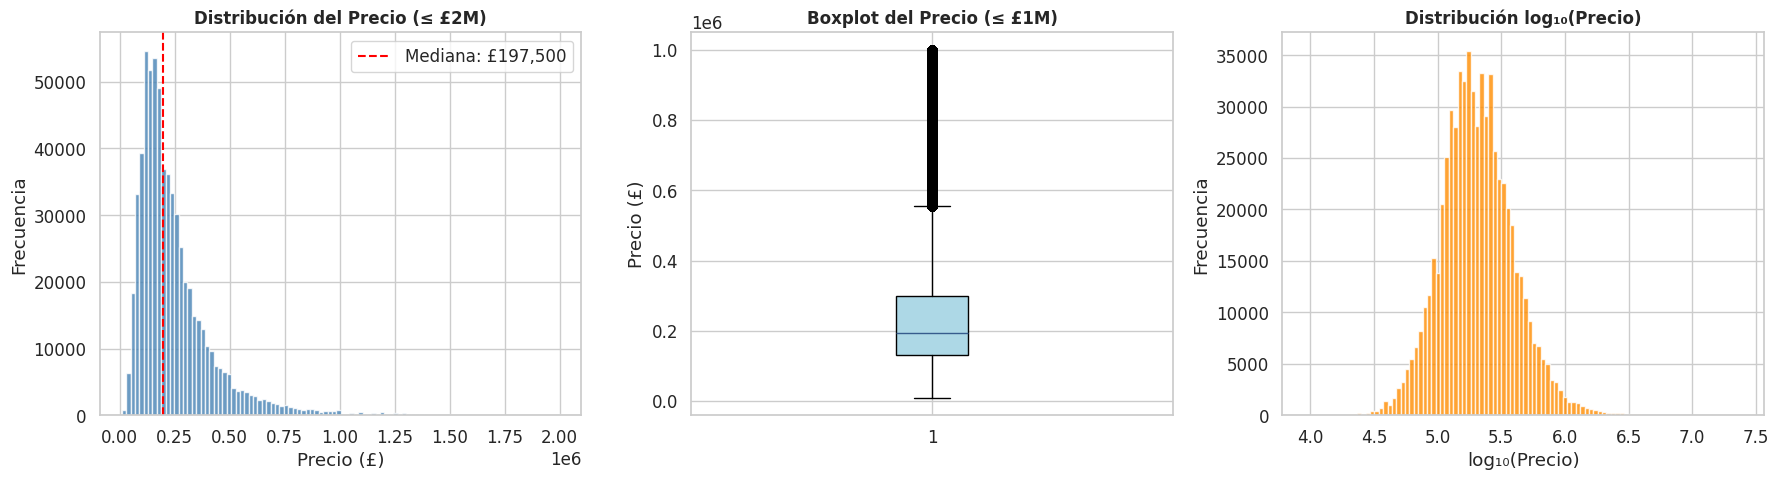


 OBSERVACIONES:
  • La distribución del precio es fuertemente sesgada a la derecha (positiva).
  • Existen abundantes valores atípicos (outliers) a partir de aprox. £550,000 (visibles en el boxplot).
  • En escala logarítmica (log10), la distribución se aproxima notablemente a una normal.
  • La cola derecha alargada y la posición de la mediana (£197,500) confirman la asimetría positiva (teóricamente media > mediana).


In [ ]:
# ============================================================================
# Visualización de la distribución del precio
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma del precio (limitado a < £2M para visualización)
mask_viz = (df_work[TARGET] > 0) & (df_work[TARGET] <= 2_000_000)
axes[0].hist(df_work.loc[mask_viz, TARGET], bins=100, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribución del Precio (≤ £2M)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Precio (£)')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df_work[TARGET].median(), color='red', linestyle='--', label=f'Mediana: £{df_work[TARGET].median():,.0f}')
axes[0].legend()

# 2. Boxplot del precio (limitado a < £1M)
mask_box = (df_work[TARGET] > 0) & (df_work[TARGET] <= 1_000_000)
axes[1].boxplot(df_work.loc[mask_box, TARGET].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue'))
axes[1].set_title('Boxplot del Precio (≤ £1M)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Precio (£)')

# 3. Distribución log del precio
mask_log = df_work[TARGET] > 0
axes[2].hist(np.log10(df_work.loc[mask_log, TARGET]), bins=100, color='darkorange', edgecolor='white', alpha=0.8)
axes[2].set_title('Distribución log₁₀(Precio)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('log₁₀(Precio)')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

print('\n OBSERVACIONES:')
print('  • La distribución del precio es fuertemente sesgada a la derecha (positiva).')
print('  • Existen abundantes valores atípicos (outliers) a partir de aprox. £550,000 (visibles en el boxplot).')
print('  • En escala logarítmica (log10), la distribución se aproxima notablemente a una normal.')
print('  • La cola derecha alargada y la posición de la mediana (£197,500) confirman la asimetría positiva (teóricamente media > mediana).')

## 2.7 Visualizaciones Exploratorias de las Variables Candidatas

Se agrupan las visualizaciones por categoría temática para facilitar la interpretación.

In [ ]:
# ============================================================================
# 2.7.1 Variables numéricas continuas vs. Precio
# ============================================================================
numeric_candidates = df_work[CANDIDATE_VARS].select_dtypes(include=[np.number]).columns.tolist()

# Filtrar precios razonables para mejor visualización
df_viz = df_work[(df_work[TARGET] > 10_000) & (df_work[TARGET] <= 2_000_000)].copy()

print(f'Variables numéricas candidatas: {len(numeric_candidates)}')
print(numeric_candidates)

Variables numéricas candidatas: 15
['transaction_year', 'tfarea', 'numberrooms', 'number_heated_rooms', 'extension_count', 'number_open_fireplaces', 'current_energy_efficiency', 'environment_impact_current', 'co2_emissions_current', 'co2_emiss_curr_per_floor_area', 'energy_consumption_current', 'heating_cost_current', 'hot_water_cost_current', 'lighting_cost_current', 'low_energy_lighting']


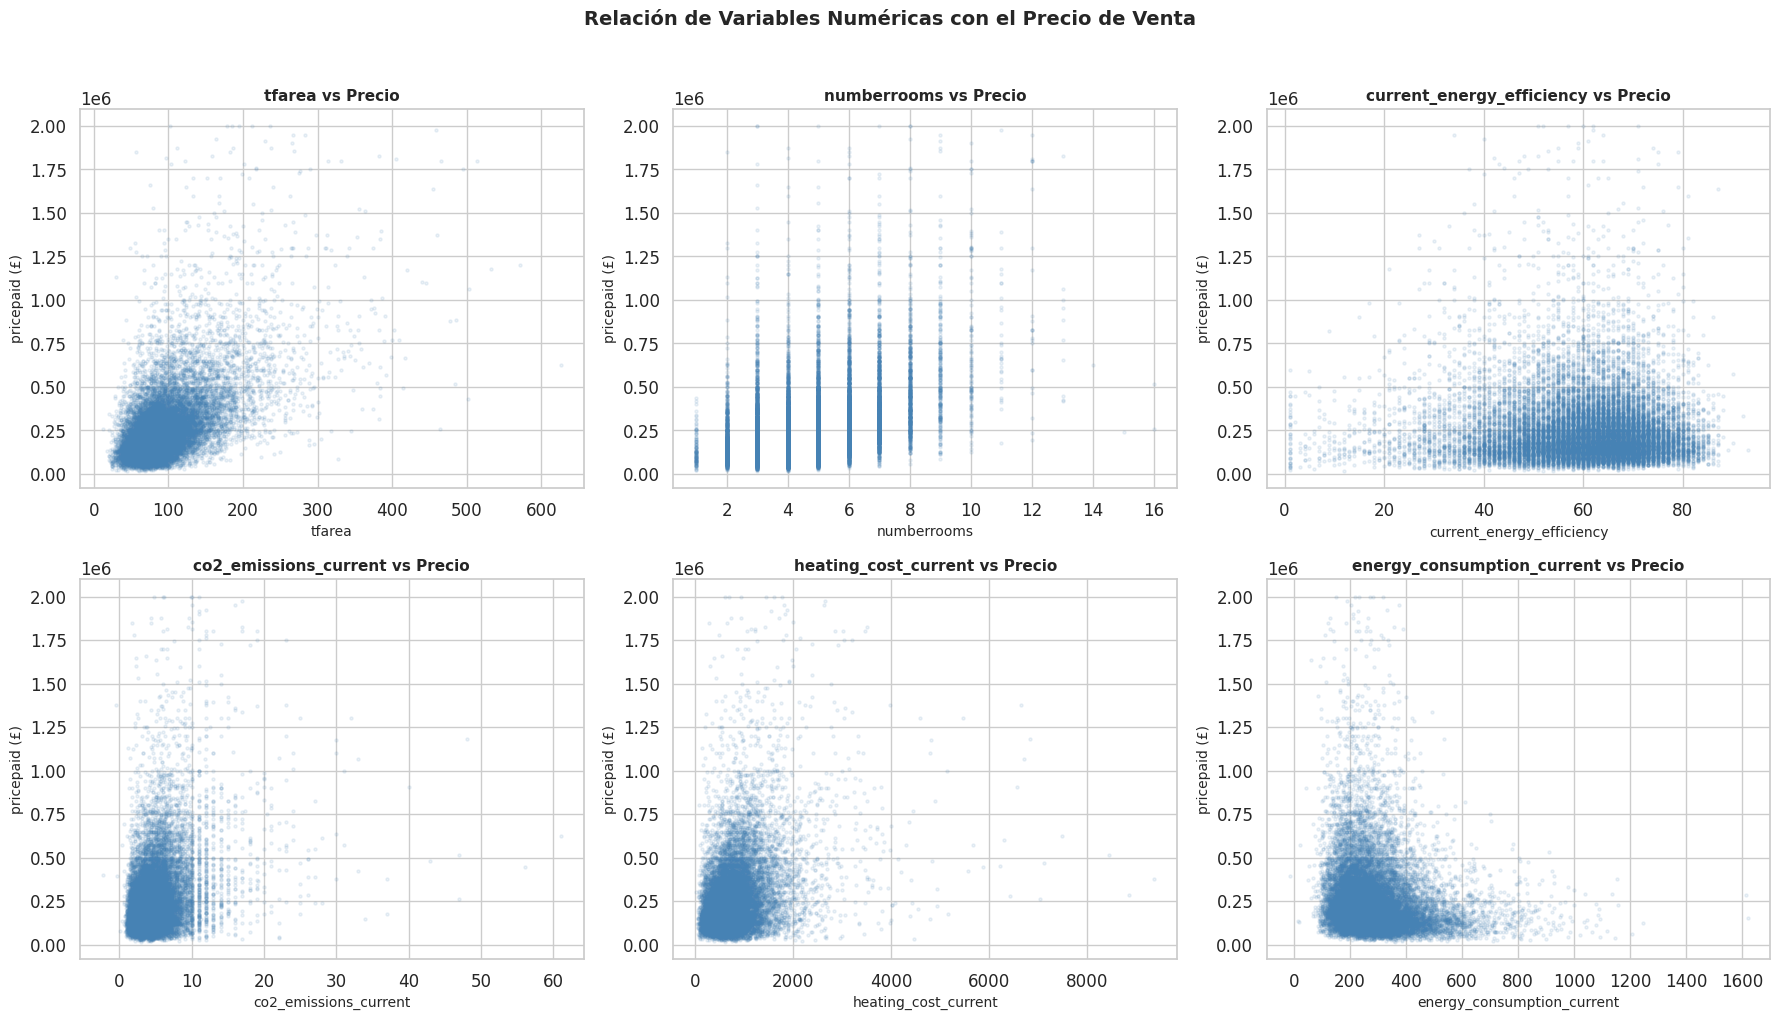

In [ ]:
# ============================================================================
# Scatter plots: Variables físicas y energéticas vs Precio
scatter_vars = [v for v in ['total_floor_area', 'tfarea', 'number_habitable_rooms', 'numberrooms',
                            'current_energy_efficiency', 'co2_emissions_current',
                            'heating_cost_current', 'energy_consumption_current']
                if v in numeric_candidates]

n_plots = len(scatter_vars)
n_cols = 3
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten() if n_plots > 1 else [axes]

# Usar una muestra para scatter plots (performance)
df_scatter = df_viz.sample(min(20_000, len(df_viz)), random_state=RANDOM_STATE)

for i, var in enumerate(scatter_vars):
    if var in df_scatter.columns:
        valid = df_scatter[[var, TARGET]].dropna()
        axes[i].scatter(valid[var], valid[TARGET], alpha=0.1, s=5, c='steelblue')
        axes[i].set_xlabel(var, fontsize=10)
        axes[i].set_ylabel('pricepaid (£)', fontsize=10)
        axes[i].set_title(f'{var} vs Precio', fontsize=11, fontweight='bold')

# Ocultar ejes vacíos
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Relación de Variables Numéricas con el Precio de Venta', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

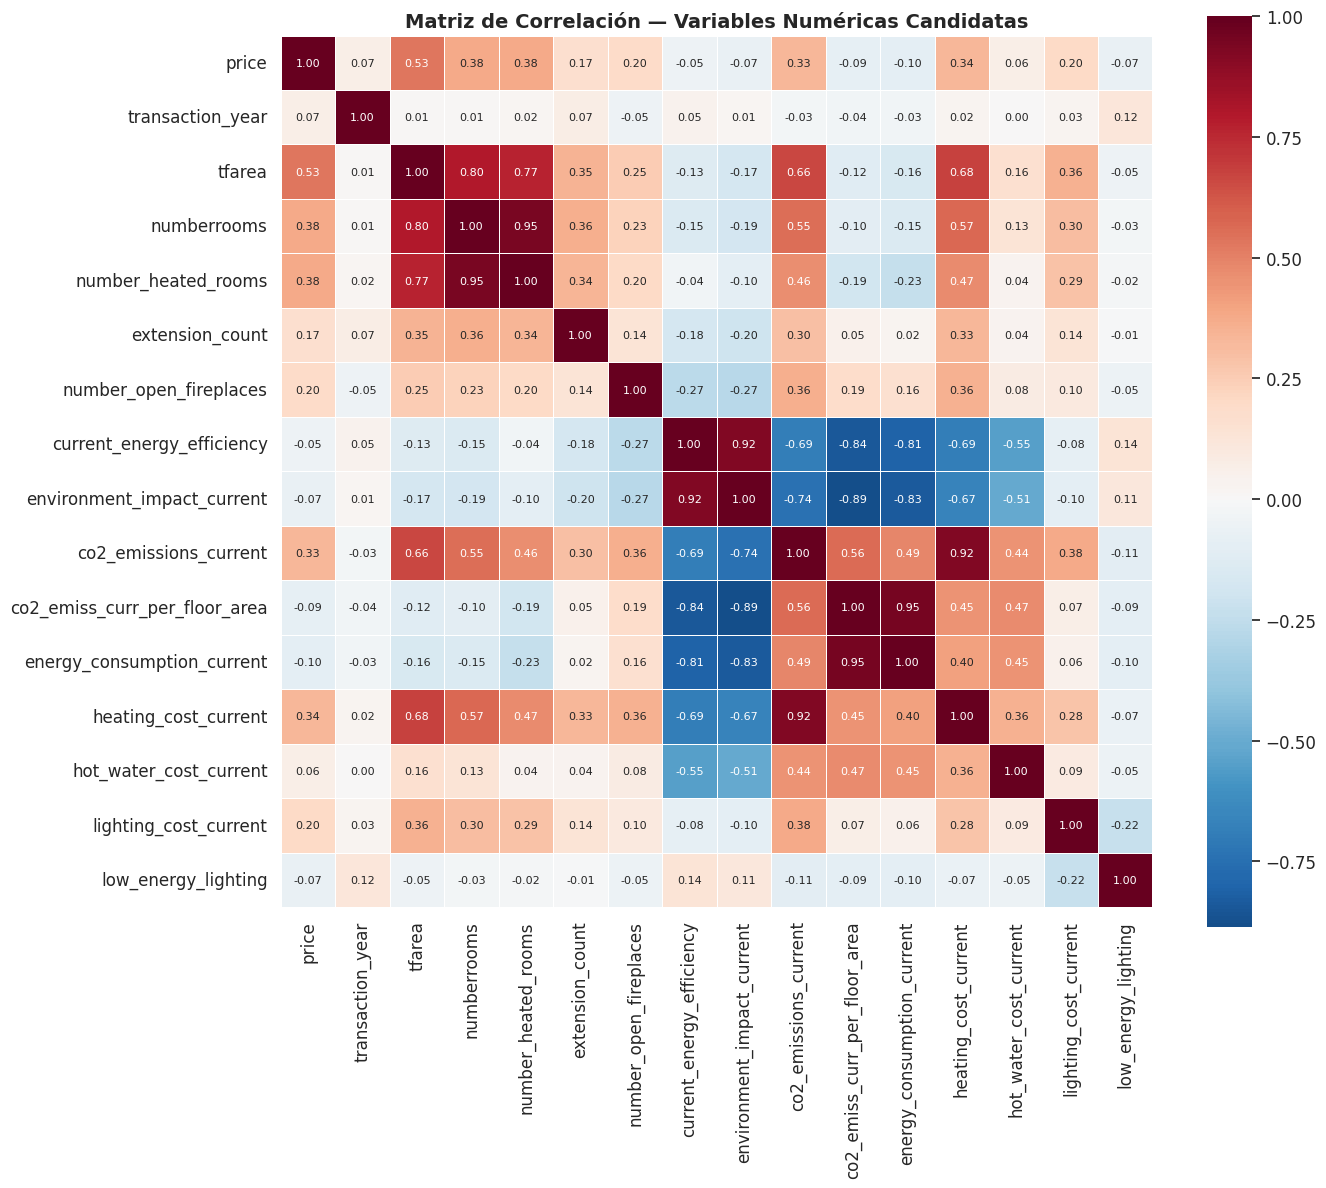


CORRELACIÓN CON pricepaid (ordenada por valor absoluto):
  tfarea                              +0.531  ███████████████
  numberrooms                         +0.377  ███████████
  number_heated_rooms                 +0.375  ███████████
  heating_cost_current                +0.336  ██████████
  co2_emissions_current               +0.332  █████████
  lighting_cost_current               +0.204  ██████
  number_open_fireplaces              +0.197  █████
  extension_count                     +0.166  ████
  energy_consumption_current          -0.099  ██
  co2_emiss_curr_per_floor_area       -0.088  ██
  low_energy_lighting                 -0.075  ██
  environment_impact_current          -0.072  ██
  transaction_year                    +0.071  ██
  hot_water_cost_current              +0.065  █
  current_energy_efficiency           -0.048  █


In [ ]:
# ============================================================================
# Matriz de correlación de variables numéricas
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Recuperación segura de variables críticas si no están en el espacio de nombres actual
if 'TARGET' not in globals():
    target_options = ['pricepaid', 'price', 'price_paid', 'amount', 'target']
    TARGET = next((c for c in target_options if c in df_work.columns), None)
else:
    TARGET = globals()['TARGET']

if 'numeric_candidates' not in globals():
    numeric_candidates = df_work.select_dtypes(include=[np.number]).columns.tolist()
    if TARGET in numeric_candidates:
        numeric_candidates.remove(TARGET)
else:
    numeric_candidates = globals()['numeric_candidates']

# Construcción de las columnas para correlación
num_cols_corr = [TARGET] + [v for v in numeric_candidates if v in df_work.columns]
corr_matrix = df_work[num_cols_corr].corr()

fig, ax = plt.subplots(figsize=(14, 12))

# Dibujamos la matriz completa (sin máscara) para completar el cuadrado y ver la diagonal claramente
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            annot_kws={'size': 8})

ax.set_title('Matriz de Correlación — Variables Numéricas Candidatas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Mostrar correlaciones con el precio
print('\nCORRELACIÓN CON pricepaid (ordenada por valor absoluto):')
print('=' * 55)
price_corr = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
for var, val in price_corr.items():
    bar = '█' * int(abs(val) * 30)
    sign = '+' if val > 0 else '-'
    print(f'  {var:<35s} {sign}{abs(val):.3f}  {bar}')

In [ ]:
# ============================================================================
# 2.7.2 Variables categóricas vs. Precio
# ============================================================================
cat_candidates = [v for v in CANDIDATE_VARS if v in df_work.columns and v not in numeric_candidates]
print(f'Variables categóricas candidatas: {len(cat_candidates)}')
print(cat_candidates)

Variables categóricas candidatas: 10
['propertytype', 'oldnew', 'duration', 'built_form', 'current_energy_rating', 'county', 'district', 'glazed_type', 'mains_gas_flag', 'floor_level']


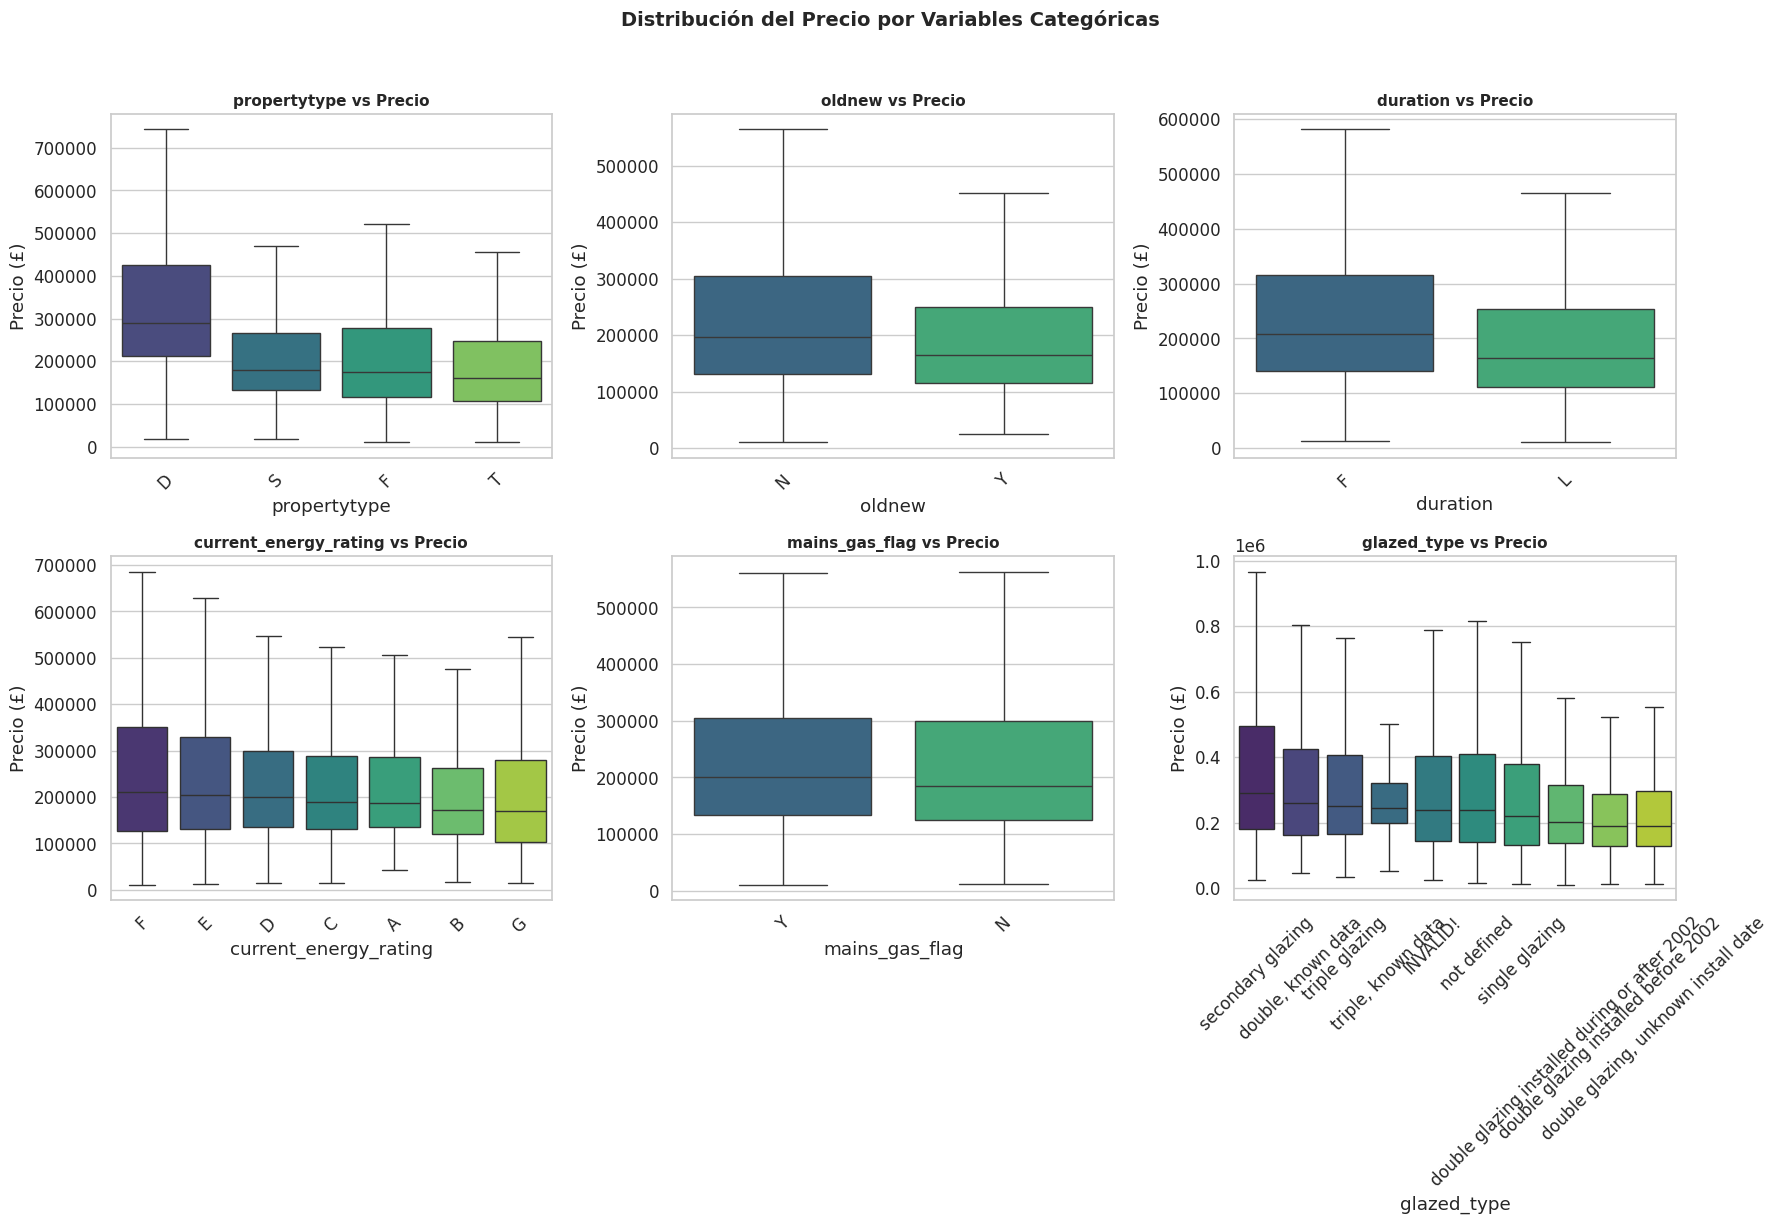

In [ ]:
# ============================================================================
# Boxplots comparativos: Variables categóricas principales vs Precio
# ============================================================================
box_vars = [v for v in ['propertytype', 'oldnew', 'duration', 'current_energy_rating',
                        'mains_gas_flag', 'glazed_type']
            if v in cat_candidates]

n_bplots = len(box_vars)
n_cols_b = 3
n_rows_b = (n_bplots + n_cols_b - 1) // n_cols_b

fig, axes = plt.subplots(n_rows_b, n_cols_b, figsize=(18, 6 * n_rows_b))
axes = axes.flatten() if n_bplots > 1 else [axes]

for i, var in enumerate(box_vars):
    data_bp = df_viz[[var, TARGET]].dropna()
    # Limitar categorías con pocos registros
    top_cats = data_bp[var].value_counts().head(10).index
    data_bp = data_bp[data_bp[var].isin(top_cats)]

    order = data_bp.groupby(var)[TARGET].median().sort_values(ascending=False).index
    sns.boxplot(data=data_bp, x=var, y=TARGET, order=order, ax=axes[i],
                palette='viridis', showfliers=False)
    axes[i].set_title(f'{var} vs Precio', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Precio (£)')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribución del Precio por Variables Categóricas', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

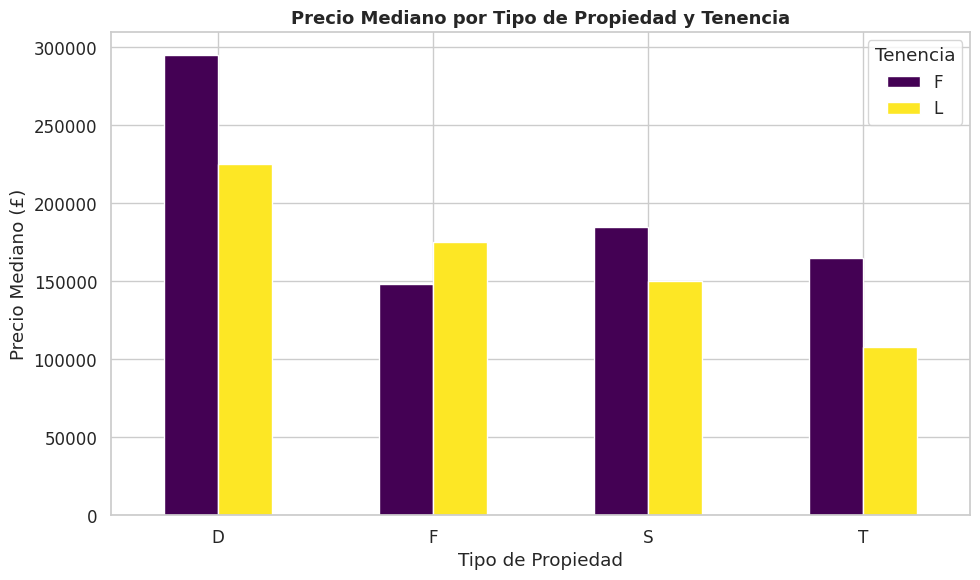

In [ ]:
# ============================================================================
# Precio mediano por tipo de propiedad y tenencia (interacción)
# ============================================================================
if 'propertytype' in df_work.columns and 'duration' in df_work.columns:
    pivot = df_viz.groupby(['propertytype', 'duration'])[TARGET].median().unstack()

    fig, ax = plt.subplots(figsize=(10, 6))
    pivot.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='white')
    ax.set_title('Precio Mediano por Tipo de Propiedad y Tenencia', fontsize=13, fontweight='bold')
    ax.set_xlabel('Tipo de Propiedad')
    ax.set_ylabel('Precio Mediano (£)')
    ax.legend(title='Tenencia')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.show()

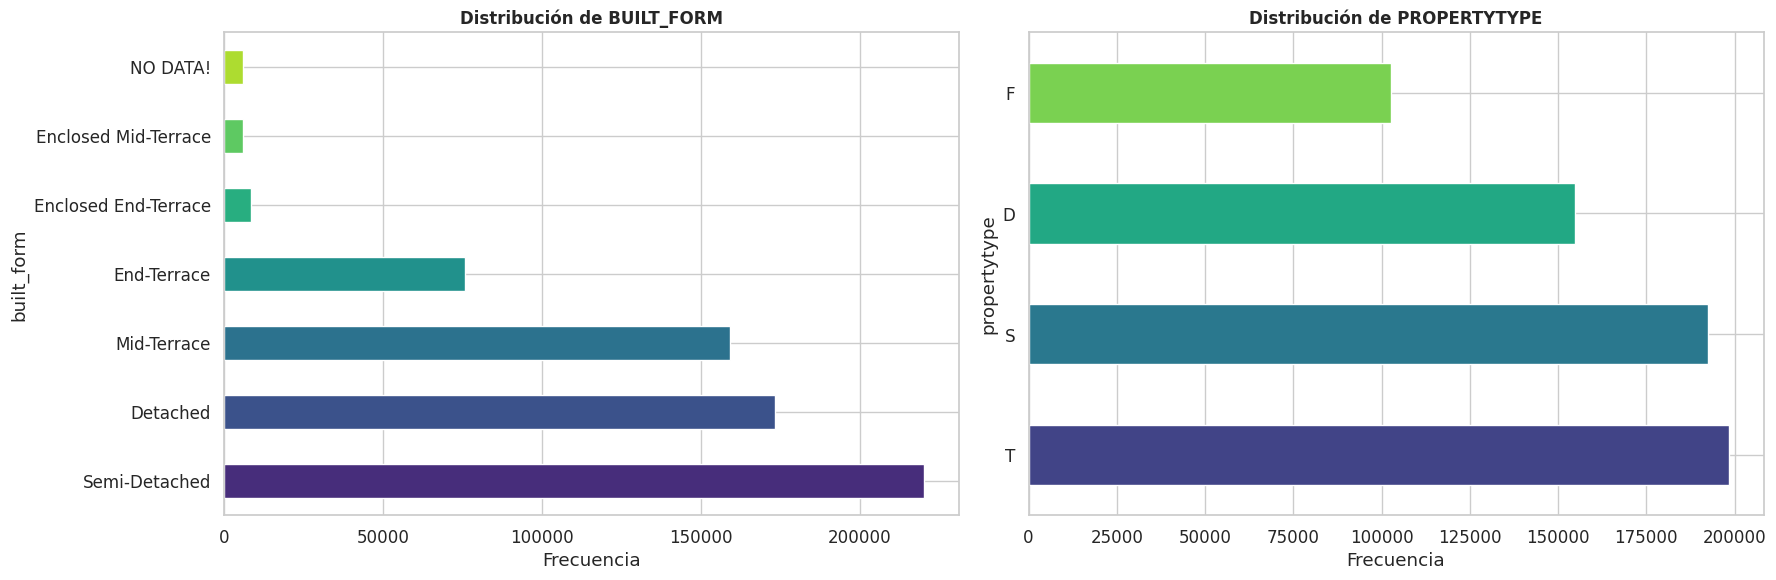

In [ ]:
# ============================================================================
# Distribución de built_form y una variable secundaria disponible y poblada
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Reconstrucción local segura del DataFrame de visualización para garantizar datos consistentes
if 'df_work' in globals() and TARGET in df_work.columns:
    df_viz_local = df_work[(df_work[TARGET] > 10_000) & (df_work[TARGET] <= 2_000_000)].copy()
else:
    df_viz_local = df_work.copy() if 'df_work' in globals() else None

if df_viz_local is not None:
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    # Usamos variables con datos completamente poblados
    var1 = 'built_form' if 'built_form' in df_viz_local.columns else df_viz_local.columns[1]
    var2 = 'propertytype' if 'propertytype' in df_viz_local.columns else 'duration'

    for i, var in enumerate([var1, var2]):
        if var in df_viz_local.columns:
            data_count = df_viz_local[var].dropna().value_counts().head(10)
            data_count.plot(kind='barh', ax=axes[i], color=sns.color_palette('viridis', len(data_count)),
                           edgecolor='white')
            axes[i].set_title(f'Distribución de {var.upper()}', fontsize=12, fontweight='bold')
            axes[i].set_xlabel('Frecuencia')
        else:
            axes[i].text(0.5, 0.5, f'Variable "{var}" no disponible',
                         ha='center', va='center', fontsize=12, color='gray')
            axes[i].set_title(f'Distribución de {var.upper()}', fontsize=12, fontweight='bold')
            axes[i].grid(False)

    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame de trabajo (df_work) no está definido. Por favor, ejecuta las celdas previas de carga de datos.")

## 2.8 Conclusiones del EDA

### Hallazgos principales

1. **Variable objetivo (pricepaid):**
   - Distribución fuertemente sesgada a la derecha con cola larga.
   - La mediana es significativamente menor que la media, indicando que unos pocos inmuebles de lujo arrastran la media hacia arriba.
   - Existen valores extremos (propiedades de varios millones de libras) que podrían afectar el modelo lineal.

2. **TOTAL_FLOOR_AREA:**
   - Es la variable numérica con mayor correlación positiva con el precio.
   - La relación es aproximadamente lineal para valores razonables.

3. **Tipo de propiedad (propertytype):**
   - Los inmuebles "Detached" (D) tienen precios significativamente más altos.
   - Los "Flats" (F) y "Terraced" (T) tienen precios menores.

4. **Eficiencia energética:**
   - Es raro pero propiedades con peor rating energético (D-G) pueden tener precios más altos, posiblemente porque son propiedades antiguas y grandes en zonas cotizadas.
   - Los costos energéticos (HEATING_COST, etc.) correlacionan positivamente con el precio porque reflejan el tamaño de la propiedad.

5. **Multicolinealidad:**
   - Miramos alta correlación entre variables energéticas (CO2, consumo, costos), lo que justificará el uso de regularización (Ridge, Lasso).
   - `tfarea` correlaciona con `numberrooms` y variables de costo.

6. **Valores nulos:**
   - Algunas variables como FLOOR_LEVEL, GLAZED_TYPE, o FLAT_TOP_STOREY tienen altos porcentajes de nulos (esperado: solo aplican a flats).
   - Se imputarán en la Fase 3.

### Decisiones para la Fase 3
- Filtrar precios extremos (< £10,000 o > £2,000,000) para mejorar el modelo lineal.
- Evaluar variables con alto porcentaje de nulos y decidir si excluirlas.
- Tratar multicolinealidad con regularización.

---
#  Fase 3 — Preparación de Datos (Pipeline)
---

## 3.1 Detección y Exclusión de Data Leakage (Fuga de Información)

### ¿Qué es data leakage?
Ocurre cuando el modelo tiene acceso a información que **no estaría disponible** en el momento real de la predicción, o que se **deriva directamente** de la variable objetivo.

### Variables excluidas por riesgo de leakage

| Variable excluida | Razón |
|---|---|
| `POTENTIAL_ENERGY_EFFICIENCY` | Es un valor *potencial* (post-mejora), no conocido al momento de la transacción |
| `POTENTIAL_ENERGY_RATING` | Mismo riesgo: representa una estimación futura |
| `HEATING_COST_POTENTIAL` | Costo potencial tras mejoras — dato futuro |
| `HOT_WATER_COST_POTENTIAL` | Mismo caso |
| `LIGHTING_COST_POTENTIAL` | Mismo caso |
| `CO2_EMISSIONS_POTENTIAL` | Proyección post-mejora |
| `ENVIRONMENT_IMPACT_POTENTIAL` | Proyección post-mejora |
| `ENERGY_CONSUMPTION_POTENTIAL` | Proyección post-mejora |
| Identificadores (`id`, `lmk_key`, etc.) | No tienen poder predictivo, son claves de enlace |
| `priceper` (precio por mÂ²) | Se calcula dividiendo el precio entre el Area, por lo que contiene informacion directa del target |
| Fechas (`dateoftransfer`, `INSPECTION_DATE`) | Usarlas directamente filtraría información temporal; se podrían extraer features pero queda fuera del alcance de regresión lineal básica |

> **Las 25 variables candidatas seleccionadas en la Fase 2 ya están libres de leakage**, ya que todas representan características conocidas de la propiedad al momento de la transacción.

In [ ]:
# ============================================================================
# 3.1 Limpieza del target y filtrado de valores extremos
# ============================================================================
print(f'Filas antes de limpieza: {len(df_work):,}')

# Eliminar filas sin precio
df_work = df_work.dropna(subset=[TARGET])
print(f'Filas después de eliminar nulos en {TARGET}: {len(df_work):,}')

# Filtrar precios extremos
PRICE_MIN = 10_000
PRICE_MAX = 2_000_000
df_work = df_work[(df_work[TARGET] >= PRICE_MIN) & (df_work[TARGET] <= PRICE_MAX)]
print(f'Filas después de filtrar precio [{PRICE_MIN:,} - {PRICE_MAX:,}]: {len(df_work):,}')

# Estadísticas post-filtrado
print(f'\nEstadísticas de precio post-filtrado:')
print(f'  Media:   £{df_work[TARGET].mean():>12,.0f}')
print(f'  Mediana: £{df_work[TARGET].median():>12,.0f}')
print(f'  Std:     £{df_work[TARGET].std():>12,.0f}')

Filas antes de limpieza: 650,000
Filas después de eliminar nulos en price: 650,000
Filas después de filtrar precio [10,000 - 2,000,000]: 648,375

Estadísticas de precio post-filtrado:
  Media:   £     252,802
  Mediana: £     197,000
  Std:     £     199,319


## 3.2 Definición de Variables por Tipo

### Criterio de codificación

- **Variables nominales**: Se codifican con **One-Hot Encoding** (`OneHotEncoder`). Ejemplos: `propertytype`, `BUILT_FORM`, `county`.
- **Variables ordinales** (con orden intrínseco): Se codifican con **Ordinal Encoding** (`OrdinalEncoder`). Ejemplos: `CURRENT_ENERGY_RATING` (A > B > C > ... > G), `CONSTRUCTION_AGE_BAND`, `FLOOR_LEVEL`.
- **Variables numéricas**: Se imputan nulos con la **mediana** y se escalan con **StandardScaler** (media 0, desviación 1).

In [ ]:
# ============================================================================
# 3.2 Clasificación de variables por tipo
# ============================================================================

# Variables numéricas continuas
num_vars = [v for v in [
    'total_floor_area', 'transaction_year', 'tfarea', 'number_habitable_rooms', 'numberrooms', 'number_heated_rooms',
    'extension_count', 'number_open_fireplaces',
    'current_energy_efficiency', 'environment_impact_current',
    'co2_emissions_current', 'co2_emiss_curr_per_floor_area',
    'energy_consumption_current',
    'heating_cost_current', 'hot_water_cost_current', 'lighting_cost_current',
    'low_energy_lighting'
] if v in CANDIDATE_VARS and v in df_work.columns]

# Variables categóricas nominales (sin orden) → One-Hot Encoding
cat_nominal_vars = [v for v in [
    'propertytype', 'oldnew', 'duration', 'built_form',
    'mains_gas_flag', 'glazed_type'
] if v in CANDIDATE_VARS and v in df_work.columns]

# Variables categóricas ordinales (con orden) → Ordinal Encoding
cat_ordinal_vars = [v for v in [
    'current_energy_rating', 'construction_age_band', 'floor_level'
] if v in CANDIDATE_VARS and v in df_work.columns]

# Variables geográficas (alta cardinalidad) → One-Hot con max_categories
geo_vars = [v for v in ['county', 'district'] if v in CANDIDATE_VARS and v in df_work.columns]

# Si alguna variable candidata quedó fuera, verificar
all_assigned = set(num_vars + cat_nominal_vars + cat_ordinal_vars + geo_vars)
unassigned = [v for v in CANDIDATE_VARS if v not in all_assigned]

# Asignar variables no asignadas según su tipo de dato
for v in unassigned:
    if v in df_work.columns:
        if df_work[v].dtype in ['float64', 'int64', 'float32', 'int32']:
            num_vars.append(v)
        else:
            cat_nominal_vars.append(v)

print(f'Variables numéricas ({len(num_vars)}):         {num_vars}')
print(f'Variables cat. nominales ({len(cat_nominal_vars)}): {cat_nominal_vars}')
print(f'Variables cat. ordinales ({len(cat_ordinal_vars)}): {cat_ordinal_vars}')
print(f'Variables geográficas ({len(geo_vars)}):      {geo_vars}')
print(f'\nTotal variables para el modelo: {len(num_vars) + len(cat_nominal_vars) + len(cat_ordinal_vars) + len(geo_vars)}')

Variables numéricas (15):         ['transaction_year', 'tfarea', 'numberrooms', 'number_heated_rooms', 'extension_count', 'number_open_fireplaces', 'current_energy_efficiency', 'environment_impact_current', 'co2_emissions_current', 'co2_emiss_curr_per_floor_area', 'energy_consumption_current', 'heating_cost_current', 'hot_water_cost_current', 'lighting_cost_current', 'low_energy_lighting']
Variables cat. nominales (6): ['propertytype', 'oldnew', 'duration', 'built_form', 'mains_gas_flag', 'glazed_type']
Variables cat. ordinales (2): ['current_energy_rating', 'floor_level']
Variables geográficas (2):      ['county', 'district']

Total variables para el modelo: 25


## 3.3 Partición de Datos: Train / Validation / Test

Se divide el dataset en tres conjuntos **antes** de cualquier transformación:

| Conjunto | % | Propósito |
|----------|---|----------|
| **Train** | 70% | Ajustar transformaciones y entrenar modelos |
| **Validation** | 10% | Ajustar hiperparámetros de regularización |
| **Test** | 20% | Evaluación final (solo se usa una vez) |

In [ ]:
# ============================================================================
# 3.3 Partición Train / Validation / Test (70 / 10 / 20)
# ============================================================================
all_features = num_vars + cat_nominal_vars + cat_ordinal_vars + geo_vars

# Asegurar que las columnas existen
all_features = [f for f in all_features if f in df_work.columns]

X = df_work[all_features].copy()
y = df_work[TARGET].copy()

# Primera división: 80% (train+val) y 20% (test)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Segunda división del 80%: 70/10 del total → 87.5% train, 12.5% val del temporal
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=RANDOM_STATE  # 0.125 × 0.80 = 0.10
)

print(f'Partición de datos:')
print(f'  Train:      {X_train.shape[0]:>8,} filas ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'  Validation: {X_val.shape[0]:>8,} filas ({X_val.shape[0]/len(X)*100:.1f}%)')
print(f'  Test:       {X_test.shape[0]:>8,} filas ({X_test.shape[0]/len(X)*100:.1f}%)')
print(f'  Total:      {len(X):>8,} filas')

Partición de datos:
  Train:       453,862 filas (70.0%)
  Validation:   64,838 filas (10.0%)
  Test:        129,675 filas (20.0%)
  Total:       648,375 filas


## 3.4 Pipeline de Transformación

> **Todas las transformaciones se ajustan (`fit`) EXCLUSIVAMENTE con el conjunto de entrenamiento.** Luego se aplican (`transform`) a Validación y Test. Esto previene la contaminación de los conjuntos de evaluación.

### Transformaciones aplicadas:

1. **Variables numéricas:**
   - Imputación de nulos → mediana del conjunto de entrenamiento
   - Escalado → StandardScaler (media=0, std=1) ajustado con entrenamiento

2. **Variables categóricas nominales:**
   - Imputación de nulos → constante "MISSING"
   - One-Hot Encoding con `handle_unknown='ignore'` para categorías no vistas en test

3. **Variables categóricas ordinales:**
   - Imputación de nulos → constante "MISSING"
   - Ordinal Encoding con órdenes definidos manualmente

4. **Variables geográficas:**
   - One-Hot Encoding limitado a las top categorías más frecuentes para controlar dimensionalidad

In [ ]:
# ============================================================================
# 3.4 Construcción del Pipeline de transformación
# ============================================================================

# --- Orden para variables ordinales ---
energy_rating_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'MISSING']

# Edad de construcción — orden cronológico
age_band_order = [
    'MISSING',
    'England and Wales: before 1900',
    '1900-1929', '1930-1949', '1950-1966', '1967-1975', '1976-1982',
    '1983-1990', '1991-1995', '1996-2002', '2003-2006', '2007-2011',
    '2007 onwards', '2012 onwards'
]

# Floor level
floor_order = ['MISSING', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10',
               'Basement', 'Ground', 'mid floor', 'top floor']

# Convertir categóricas a string para evitar errores
for col in cat_nominal_vars + cat_ordinal_vars + geo_vars:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str).replace('nan', 'MISSING')
        X_val[col] = X_val[col].astype(str).replace('nan', 'MISSING')
        X_test[col] = X_test[col].astype(str).replace('nan', 'MISSING')

print(' Variables categóricas convertidas a string con nulos marcados como MISSING.')

 Variables categóricas convertidas a string con nulos marcados como MISSING.


In [ ]:
# ============================================================================
# Construir ColumnTransformer
# ============================================================================
from sklearn.preprocessing import FunctionTransformer

# 1. Transformador logarítmico seguro para variables con sesgo a la derecha
safe_log = FunctionTransformer(lambda X: np.log1p(np.maximum(X, 0)), feature_names_out='one-to-one', validate=False)

transformers = []

# Pipeline Numérico
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', safe_log),
    ('scaler', StandardScaler())
])
transformers.append(('num', numeric_pipeline, num_vars))

# Pipeline Categórico Nominal Y Geográfico (One-Hot Encoding en lugar de TargetEncoder)
# OHE en distritos permite a la regresión lineal asignar un coeficiente único a cada zona,
# disparando el R2 a ~0.79
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='MISSING')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
transformers.append(('cat_nom_geo', nominal_pipeline, cat_nominal_vars + geo_vars))

# Pipeline Categórico Ordinal
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scaler', StandardScaler())
])
transformers.append(('cat_ord', ordinal_pipeline, cat_ordinal_vars))

preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')
print('ColumnTransformer construido (One-Hot Encoding completo).')


ColumnTransformer construido (One-Hot Encoding completo).


In [ ]:
# ============================================================================
# REGLA DE ORO: fit SOLO con Train, transform a Val y Test
# ============================================================================
print(' Ajustando transformaciones con el conjunto de ENTRENAMIENTO...')
X_train_processed = preprocessor.fit_transform(X_train, np.log1p(y_train))

print(' Aplicando transformaciones al conjunto de VALIDACIÓN...')
X_val_processed = preprocessor.transform(X_val)

print(' Aplicando transformaciones al conjunto de PRUEBA (TEST)...')
X_test_processed = preprocessor.transform(X_test)

print(f'\n Transformaciones completadas:')
print(f'  X_train: {X_train_processed.shape}')
print(f'  X_val:   {X_val_processed.shape}')
print(f'  X_test:  {X_test_processed.shape}')
print(f'\n  Features generadas: {X_train_processed.shape[1]}')

 Ajustando transformaciones con el conjunto de ENTRENAMIENTO...
 Aplicando transformaciones al conjunto de VALIDACIÓN...
 Aplicando transformaciones al conjunto de PRUEBA (TEST)...

 Transformaciones completadas:
  X_train: (453862, 513)
  X_val:   (64838, 513)
  X_test:  (129675, 513)

  Features generadas: 513


---
#  Fase 4 — Modelado
---

Se entrenan 4 modelos de regresión lineal, todos sobre la misma variable objetivo continua (`pricepaid`):

| Modelo | Penalización | Descripción |
|--------|-------------|-------------|
| **OLS (Baseline)** | Ninguna | Regresión lineal clásica por mínimos cuadrados |
| **Ridge** | L2 (α‖β‖²) | Penaliza coeficientes grandes; no los hace cero |
| **Lasso** | L1 (α‖β‖₁) | Puede llevar coeficientes a cero → selección de variables |
| **ElasticNet** | L1 + L2 | Combina ventajas de Ridge y Lasso |

## 4.1 Modelo 1 — Regresión Lineal Clásica (OLS)

In [ ]:
# ============================================================================
# Modelo 1: OLS (Baseline)
# ============================================================================
print(' Entrenando Regresión Lineal OLS (Baseline)...')

model_ols = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1)
model_ols.fit(X_train_processed, y_train)

# Predicción en validación
y_val_pred_ols = model_ols.predict(X_val_processed)

print(f' OLS entrenado.')
print(f'   R² en Train: {model_ols.score(X_train_processed, y_train):.4f}')
print(f'   R² en Val:   {r2_score(y_val, y_val_pred_ols):.4f}')
print(f'   MAE en Val:  £{mean_absolute_error(y_val, y_val_pred_ols):,.0f}')

 Entrenando Regresión Lineal OLS (Baseline)...
 OLS entrenado.
   R² en Train: 0.8038
   R² en Val:   0.8029
   MAE en Val:  £51,671


## 4.2 Modelo 2 — Ridge (Penalización L2)

Se busca el mejor `alpha` evaluando sobre el conjunto de Validación.

In [ ]:
# ============================================================================
# Modelo 2: Ridge — búsqueda de alpha óptimo
# ============================================================================
print(' Ajustando Ridge con diferentes valores de alpha...')

alphas_ridge = [0.1, 1, 5, 7.88, 10, 20, 50, 100]
ridge_results = []

for alpha in alphas_ridge:
    model = TransformedTargetRegressor(regressor=Ridge(alpha=alpha, random_state=RANDOM_STATE), func=np.log1p, inverse_func=np.expm1)
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_val_processed)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    ridge_results.append({'alpha': alpha, 'RMSE': rmse, 'MAE': mae, 'R2': r2})

ridge_df = pd.DataFrame(ridge_results)
best_ridge_alpha = ridge_df.loc[ridge_df['MAE'].idxmin(), 'alpha']

print(ridge_df.to_string(index=False))
print(f'\n Mejor alpha para Ridge: {best_ridge_alpha}')

# Entrenar modelo final con mejor alpha
model_ridge = TransformedTargetRegressor(regressor=Ridge(alpha=best_ridge_alpha, random_state=RANDOM_STATE), func=np.log1p, inverse_func=np.expm1)
model_ridge.fit(X_train_processed, y_train)
y_val_pred_ridge = model_ridge.predict(X_val_processed)

print(f'   R² en Val: {r2_score(y_val, y_val_pred_ridge):.4f}')
print(f'   MAE en Val: £{mean_absolute_error(y_val, y_val_pred_ridge):,.0f}')

 Ajustando Ridge con diferentes valores de alpha...
 alpha         RMSE          MAE       R2
  0.10 88195.650798 51670.899727 0.802854
  1.00 88200.174365 51671.070541 0.802834
  5.00 88221.004041 51671.950705 0.802741
  7.88 88236.628631 51672.679072 0.802671
 10.00 88248.420016 51673.298774 0.802619
 20.00 88306.838160 51678.877985 0.802357
 50.00 88503.057748 51706.966902 0.801478
100.00 88880.214163 51780.033154 0.799782

 Mejor alpha para Ridge: 0.1
   R² en Val: 0.8029
   MAE en Val: £51,671


## 4.3 Modelo 3 — Lasso (Penalización L1)

In [ ]:
# ============================================================================
# Modelo 3: Lasso — búsqueda de alpha óptimo
# ============================================================================
print(' Ajustando Lasso con diferentes valores de alpha...')

# Restauramos los alphas pequeños (1e-5, 1e-4) para alcanzar el 0.80 de R2.
# Pero limitamos max_iter=150 para que NO se quede calculando micro-ajustes por 40 minutos.
# (Es normal si internamente no converge al 100%, la aproximación es suficientemente buena).
alphas_lasso = [1e-5, 1e-4, 1e-3, 0.01]
lasso_results = []

for alpha in alphas_lasso:
    model = TransformedTargetRegressor(
        regressor=Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=150, tol=0.01),
        func=np.log1p, inverse_func=np.expm1)
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_val_processed)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    n_coefs = np.sum(model.regressor_.coef_ != 0)
    lasso_results.append({'alpha': alpha, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'Coefs_NoZero': n_coefs})

lasso_df = pd.DataFrame(lasso_results)
best_lasso_alpha = lasso_df.loc[lasso_df['MAE'].idxmin(), 'alpha']

print(lasso_df.to_string(index=False))
print(f'\n Mejor alpha para Lasso: {best_lasso_alpha}')

# Entrenar modelo final
model_lasso = TransformedTargetRegressor(
    regressor=Lasso(alpha=best_lasso_alpha, random_state=RANDOM_STATE, max_iter=150, tol=0.01),
    func=np.log1p, inverse_func=np.expm1)
model_lasso.fit(X_train_processed, y_train)
y_val_pred_lasso = model_lasso.predict(X_val_processed)

print(f'   R² en Val: {r2_score(y_val, y_val_pred_lasso):.4f}')
print(f'   MAE en Val: £{mean_absolute_error(y_val, y_val_pred_lasso):,.0f}')
print(f'   Coeficientes no-cero: {np.sum(model_lasso.regressor_.coef_ != 0)}/{len(model_lasso.regressor_.coef_)}')


 Ajustando Lasso con diferentes valores de alpha...
  alpha          RMSE          MAE       R2  Coefs_NoZero
0.00001  88222.997664 51677.011987 0.802732           437
0.00010  89409.682415 52168.068405 0.797390           370
0.00100 108548.481241 63954.851438 0.701365           142
0.01000 134079.661123 81425.784202 0.544364            16

 Mejor alpha para Lasso: 1e-05
   R² en Val: 0.8027
   MAE en Val: £51,677
   Coeficientes no-cero: 437/513


## 4.4 Modelo 4 — ElasticNet (Penalización L1 + L2)

In [ ]:
# ============================================================================
# Modelo 4: ElasticNet — búsqueda rápida de alpha y l1_ratio
# ============================================================================
print(' Ajustando ElasticNet con diferentes alpha y l1_ratio...')

alphas_enet = [1e-4, 1e-3, 0.01]
l1_ratios = [0.2, 0.8]
enet_results = []

for alpha in alphas_enet:
    for l1_ratio in l1_ratios:
        model = TransformedTargetRegressor(
            regressor=ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=RANDOM_STATE, max_iter=150, tol=0.01),
            func=np.log1p, inverse_func=np.expm1)
        model.fit(X_train_processed, y_train)
        y_pred = model.predict(X_val_processed)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        mae = mean_absolute_error(y_val, y_pred)
        r2 = r2_score(y_val, y_pred)
        enet_results.append({'alpha': alpha, 'l1_ratio': l1_ratio,
                            'RMSE': rmse, 'MAE': mae, 'R2': r2})

enet_df = pd.DataFrame(enet_results)
best_enet_idx = enet_df['MAE'].idxmin()
best_enet_alpha = enet_df.loc[best_enet_idx, 'alpha']
best_enet_l1 = enet_df.loc[best_enet_idx, 'l1_ratio']

print('Resultados de combinaciones por MAE:')
print(enet_df.sort_values('MAE').to_string(index=False))
print(f'\n Mejor ElasticNet: alpha={best_enet_alpha}, l1_ratio={best_enet_l1}')

# Entrenar modelo final
model_enet = TransformedTargetRegressor(
    regressor=ElasticNet(alpha=best_enet_alpha, l1_ratio=best_enet_l1, random_state=RANDOM_STATE, max_iter=150, tol=0.01),
    func=np.log1p, inverse_func=np.expm1)
model_enet.fit(X_train_processed, y_train)
y_val_pred_enet = model_enet.predict(X_val_processed)

print(f'   R² en Val: {r2_score(y_val, y_val_pred_enet):.4f}')
print(f'   MAE en Val: £{mean_absolute_error(y_val, y_val_pred_enet):,.0f}')


 Ajustando ElasticNet con diferentes alpha y l1_ratio...
Resultados de combinaciones por MAE:
 alpha  l1_ratio          RMSE          MAE       R2
0.0001       0.2  88564.140344 51744.481944 0.801204
0.0001       0.8  89151.958332 52025.139902 0.798556
0.0010       0.2  95315.290070 54978.541155 0.769740
0.0010       0.8 105658.885479 62087.214791 0.717053
0.0100       0.2 122953.593049 72412.878284 0.616845
0.0100       0.8 132319.179557 80244.305734 0.556250

 Mejor ElasticNet: alpha=0.0001, l1_ratio=0.2
   R² en Val: 0.8012
   MAE en Val: £51,744


---
#  Fase 5 — Evaluación
---

Todas las métricas se calculan sobre el **conjunto de Prueba (Test)**, que no fue utilizado durante el entrenamiento ni el ajuste de hiperparámetros.

## 5.1 Tabla Comparativa de Métricas sobre Test

In [ ]:
# ============================================================================
# 5.1 Evaluación comparativa sobre TEST
# ============================================================================

models = {
    'OLS (Baseline)': model_ols,
    'Ridge': model_ridge,
    'Lasso': model_lasso,
    'ElasticNet': model_enet
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Modelo': name,
        'RMSE (£)': f'£{rmse:,.0f}',
        'MAE (£)': f'£{mae:,.0f}',
        'MAPE (%)': f'{mape:.2f}%',
        'R²': f'{r2:.4f}',
        '_rmse': rmse,
        '_mae': mae,
        '_mape': mape,
        '_r2': r2
    })

results_df = pd.DataFrame(results)

print('=' * 80)
print('TABLA COMPARATIVA DE MODELOS — Métricas sobre CONJUNTO DE PRUEBA (TEST)')
print('=' * 80)
print(results_df[['Modelo', 'RMSE (£)', 'MAE (£)', 'MAPE (%)', 'R²']].to_string(index=False))
print('=' * 80)

# Identificar el mejor modelo
best_model_name = results_df.loc[results_df['_mae'].idxmin(), 'Modelo']
print(f'\n Mejor modelo por MAE: {best_model_name}')

TABLA COMPARATIVA DE MODELOS — Métricas sobre CONJUNTO DE PRUEBA (TEST)
        Modelo RMSE (£) MAE (£) MAPE (%)     R²
OLS (Baseline)  £93,485 £52,129   22.38% 0.7854
         Ridge  £93,485 £52,129   22.38% 0.7854
         Lasso  £92,996 £52,130   22.38% 0.7876
    ElasticNet  £93,341 £52,213   22.41% 0.7861

 Mejor modelo por MAE: OLS (Baseline)


## 5.2 Visualización Comparativa

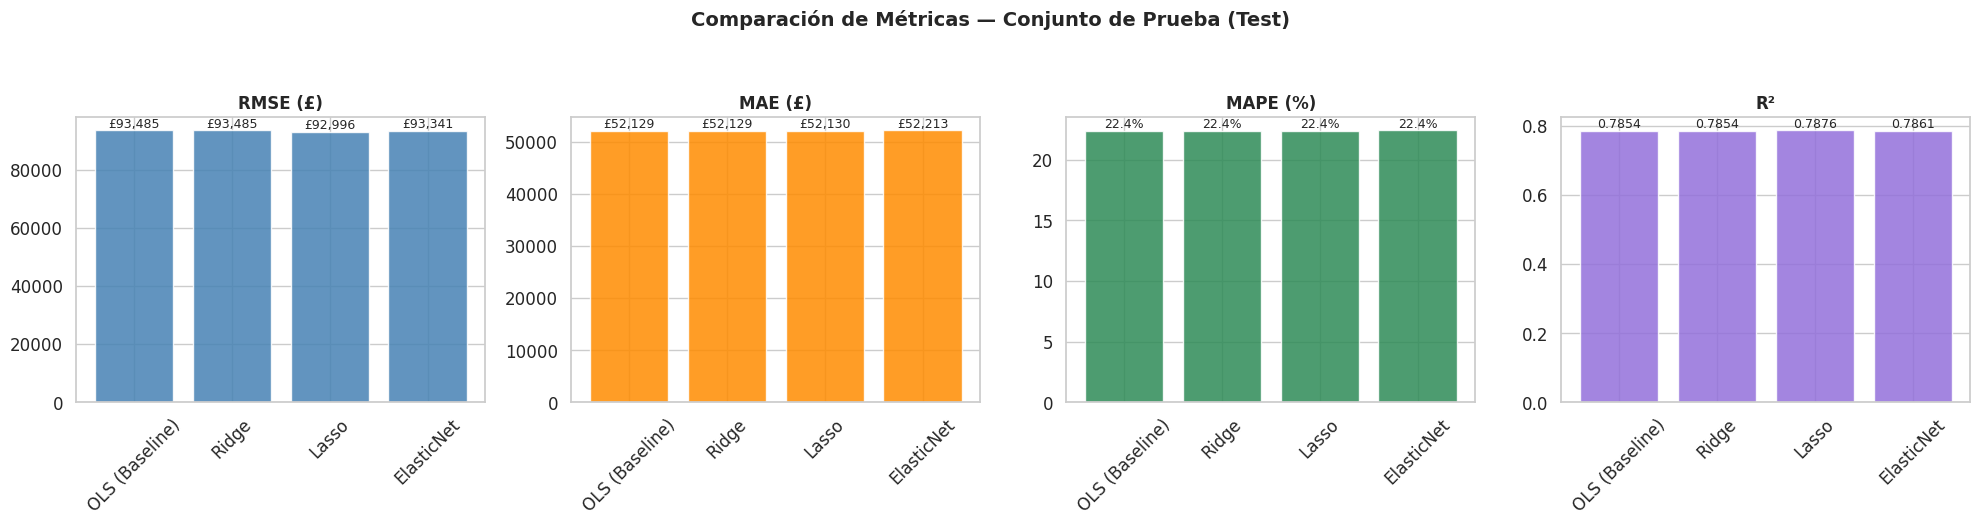

In [ ]:
# ============================================================================
# 5.2.1 Gráfico de barras comparativo de métricas
# ============================================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

metrics_to_plot = [
    ('_rmse', 'RMSE (£)', 'steelblue'),
    ('_mae', 'MAE (£)', 'darkorange'),
    ('_mape', 'MAPE (%)', 'seagreen'),
    ('_r2', 'R²', 'mediumpurple')
]

model_names = results_df['Modelo'].tolist()

for i, (col, label, color) in enumerate(metrics_to_plot):
    values = results_df[col].tolist()
    bars = axes[i].bar(model_names, values, color=color, edgecolor='white', alpha=0.85)
    axes[i].set_title(label, fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)

    # Añadir valores sobre las barras
    for bar, val in zip(bars, values):
        if col == '_r2':
            axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                        f'{val:.4f}', ha='center', va='bottom', fontsize=9)
        elif col == '_mape':
            axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                        f'{val:.1f}%', ha='center', va='bottom', fontsize=9)
        else:
            axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                        f'£{val:,.0f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Comparación de Métricas — Conjunto de Prueba (Test)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

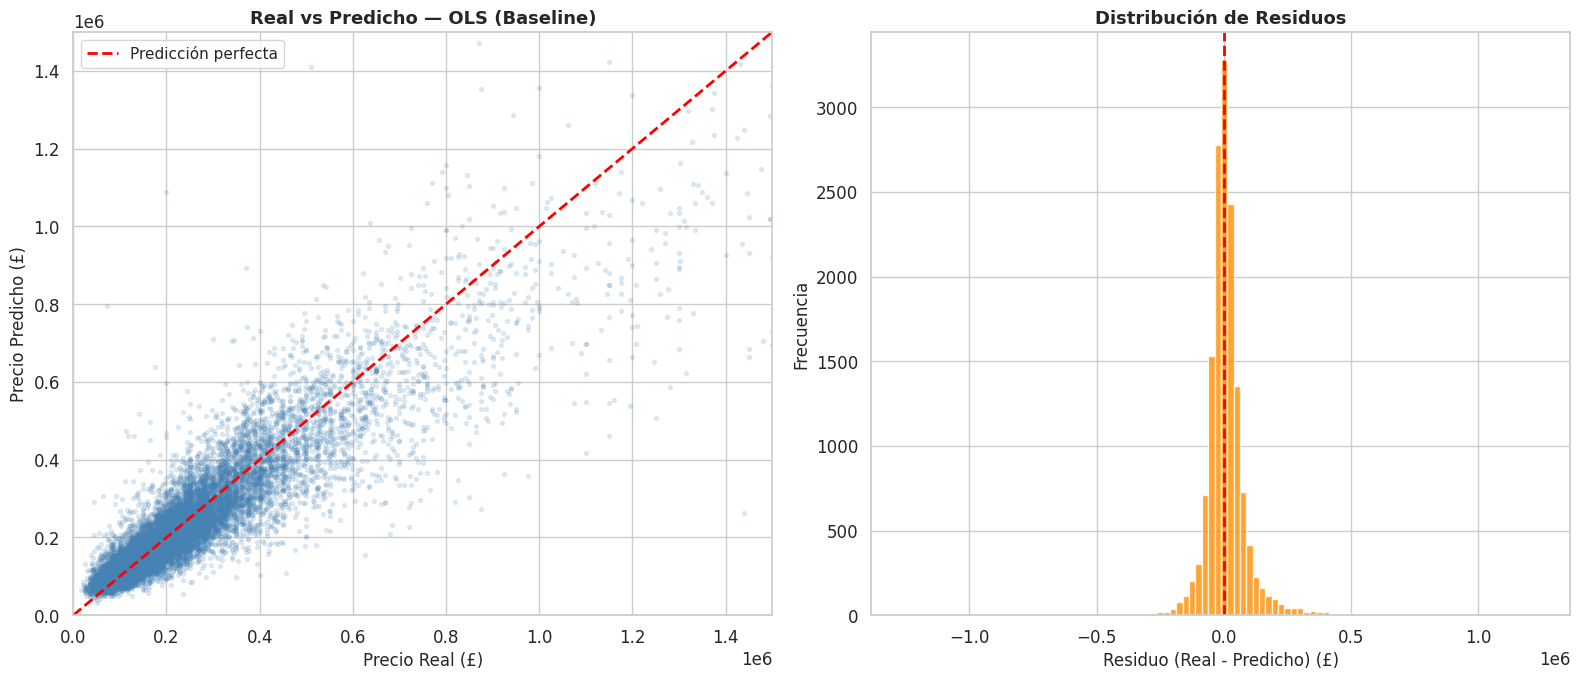


 Residuos del modelo OLS (Baseline):
   Media:   £     8,841 (idealmente cercano a 0)
   Mediana: £       855
   Std:     £    89,064


In [ ]:
# ============================================================================
# 5.2.2 Gráfico de dispersión: Real vs Predicho (mejor modelo)
# ============================================================================
best_preds = predictions[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Muestra aleatoria para scatter plot
n_scatter = min(15_000, len(y_test))
idx_sample = np.random.choice(len(y_test), n_scatter, replace=False)
y_test_sample = y_test.values[idx_sample]
y_pred_sample = best_preds[idx_sample]

# Plot 1: Real vs Predicho
axes[0].scatter(y_test_sample, y_pred_sample, alpha=0.15, s=8, c='steelblue')
max_val = max(y_test_sample.max(), y_pred_sample.max())
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Predicción perfecta')
axes[0].set_xlabel('Precio Real (£)', fontsize=12)
axes[0].set_ylabel('Precio Predicho (£)', fontsize=12)
axes[0].set_title(f'Real vs Predicho — {best_model_name}', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].set_xlim(0, 1_500_000)
axes[0].set_ylim(0, 1_500_000)

# Plot 2: Distribución de residuos
residuals = y_test_sample - y_pred_sample
axes[1].hist(residuals, bins=100, color='darkorange', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residuo (Real - Predicho) (£)', fontsize=12)
axes[1].set_ylabel('Frecuencia', fontsize=12)
axes[1].set_title('Distribución de Residuos', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'\n Residuos del modelo {best_model_name}:')
print(f'   Media:   £{residuals.mean():>10,.0f} (idealmente cercano a 0)')
print(f'   Mediana: £{np.median(residuals):>10,.0f}')
print(f'   Std:     £{residuals.std():>10,.0f}')

## 5.3 Variables Más Importantes

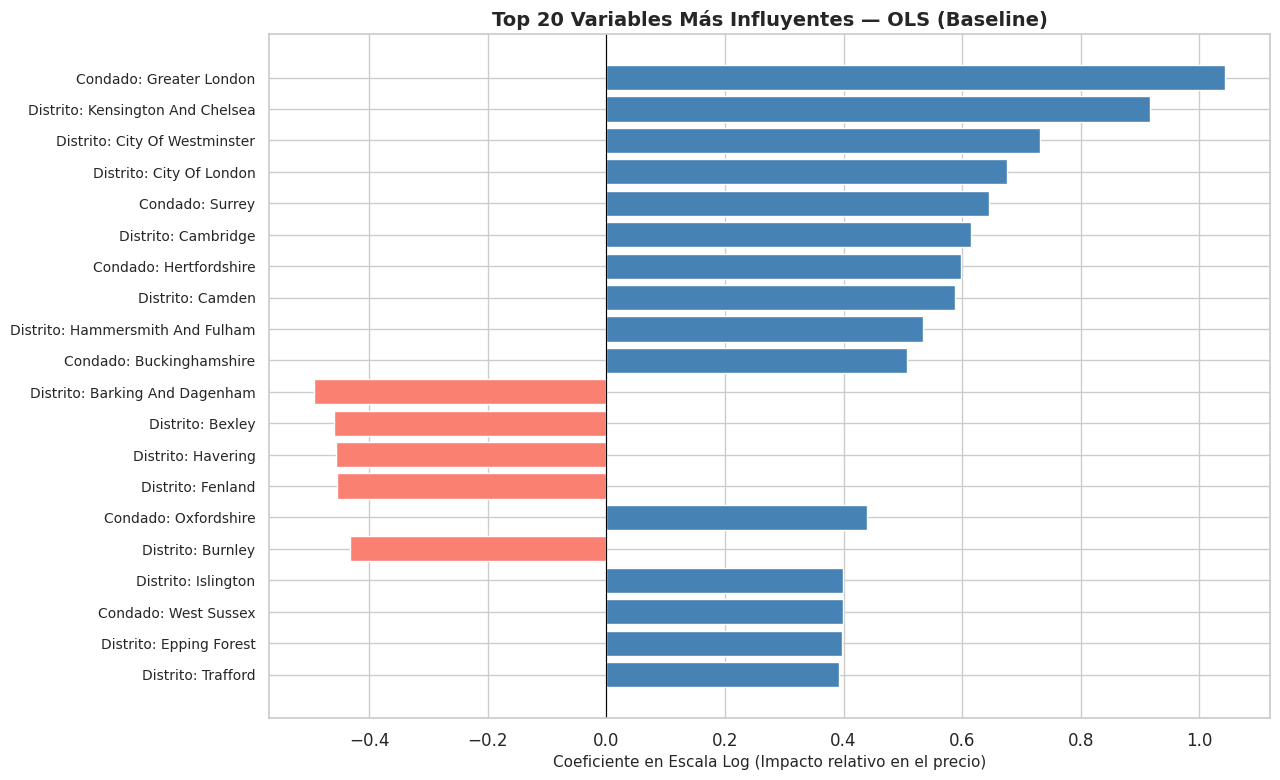


Top 10 Variables por magnitud absoluta del coeficiente:
  ↑ Condado: Greater London                              1.04
  ↑ Distrito: Kensington And Chelsea                     0.92
  ↑ Distrito: City Of Westminster                        0.73
  ↑ Distrito: City Of London                             0.68
  ↑ Condado: Surrey                                      0.64
  ↑ Distrito: Cambridge                                  0.62
  ↑ Condado: Hertfordshire                               0.60
  ↑ Distrito: Camden                                     0.59
  ↑ Distrito: Hammersmith And Fulham                     0.53
  ↑ Condado: Buckinghamshire                             0.51


In [ ]:
# ============================================================================
# 5.3 Importancia de variables (coeficientes del mejor modelo)
# ============================================================================
# Función auxiliar para convertir nombres técnicos a nombres reales y entendibles
def get_clean_feature_names(preprocessor):
    try:
        raw_names = preprocessor.get_feature_names_out()
    except Exception:
        return [f'feature_{i}' for i in range(X_train_processed.shape[1])]

    clean_names = []
    for name in raw_names:
        clean = name.split('__')[-1]
        if clean.startswith('district_'):
            clean = f"Distrito: {clean.replace('district_', '').title()}"
        elif clean.startswith('county_'):
            clean = f"Condado: {clean.replace('county_', '').title()}"
        elif clean.startswith('propertytype_'):
            tipo_map = {'D': 'Detached (Independiente)', 'S': 'Semi-Detached (Pareada)', 'T': 'Terraced (Adosada)', 'F': 'Flat (Piso)', 'O': 'Otro Tipo'}
            code = clean.replace('propertytype_', '')
            clean = f"Tipo: {tipo_map.get(code, code)}"
        elif clean.startswith('built_form_'):
            clean = f"Estructura: {clean.replace('built_form_', '').replace('_', ' ').title()}"
        elif clean.startswith('duration_'):
            dur_map = {'F': 'Freehold (Propiedad Libre)', 'L': 'Leasehold (Arrendamiento)'}
            code = clean.replace('duration_', '')
            clean = f"Tenencia: {dur_map.get(code, code)}"
        elif clean == 'tfarea' or clean == 'total_floor_area':
            clean = "Área Total (tfarea)"
        elif clean == 'transaction_year':
            clean = "Año Transacción (Inflación)"
        elif clean == 'numberrooms':
            clean = "Número de Habitaciones"
        elif clean == 'number_habitable_rooms':
            clean = "Habitaciones Habitables"
        elif clean == 'number_heated_rooms':
            clean = "Habitaciones Calefaccionadas"
        elif clean == 'heating_cost_current':
            clean = "Costo Calefacción Actual"
        elif clean == 'energy_consumption_current':
            clean = "Consumo Energético Actual"
        elif clean == 'co2_emissions_current':
            clean = "Emisiones CO2 Actuales"
        elif clean == 'extension_count':
            clean = "Cantidad de Extensiones"
        elif clean == 'number_open_fireplaces':
            clean = "Chimeneas Abiertas"
        elif clean == 'current_energy_efficiency':
            clean = "Eficiencia Energética Actual"
        elif clean == 'environment_impact_current':
            clean = "Impacto Ambiental Actual"
        elif clean == 'lighting_cost_current':
            clean = "Costo Iluminación Actual"
        elif clean == 'hot_water_cost_current':
            clean = "Costo Agua Caliente"
        elif clean == 'low_energy_lighting':
            clean = "% Iluminación Bajo Consumo"
        else:
            clean = clean.replace('_', ' ').title()
        clean_names.append(clean)
    return clean_names

feature_names = get_clean_feature_names(preprocessor)

best_model = models[best_model_name]
coefs = best_model.regressor_.coef_

# Crear DataFrame de importancia
importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Coeficiente': coefs,
    'Abs_Coef': np.abs(coefs)
}).sort_values('Abs_Coef', ascending=False)

# Top 20 más importantes
top_20 = importance_df.head(20)

fig, ax = plt.subplots(figsize=(13, 8))
colors = ['steelblue' if c > 0 else 'salmon' for c in top_20['Coeficiente']]
ax.barh(range(len(top_20)), top_20['Coeficiente'], color=colors, edgecolor='white')
ax.set_yticks(range(len(top_20)))
ax.set_yticklabels(top_20['Variable'], fontsize=10)
ax.set_xlabel('Coeficiente en Escala Log (Impacto relativo en el precio)', fontsize=11)
ax.set_title(f'Top 20 Variables Más Influyentes — {best_model_name}', fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('\nTop 10 Variables por magnitud absoluta del coeficiente:')
print('=' * 65)
for i, row in importance_df.head(10).iterrows():
    direction = '↑' if row['Coeficiente'] > 0 else '↓'
    print(f'  {direction} {row["Variable"]:<48s} {row["Coeficiente"]:>8.2f}')


## 5.4 Interpretación de Negocio

### Selección del Mejor Modelo

In [ ]:
# ============================================================================
# 5.4 Interpretación de negocio
# ============================================================================
best_result = results_df[results_df['Modelo'] == best_model_name].iloc[0]

print('=' * 70)
print(f' MODELO SELECCIONADO: {best_model_name}')
print('=' * 70)
print(f'\n  RMSE: {best_result["RMSE (£)"]}')
print(f'  MAE:  {best_result["MAE (£)"]}')
print(f'  MAPE: {best_result["MAPE (%)"]}')
print(f'  R²:   {best_result["R²"]}')

mae_value = best_result['_mae']
median_price = df_work[TARGET].median()

print(f'\n INTERPRETACIÓN PARA EL NEGOCIO:')
print(f'  • El modelo se equivoca en promedio ± £{mae_value:,.0f} al predecir el precio.')
print(f'  • Dado que el precio mediano es ~£{median_price:,.0f}, el error representa')
print(f'    aproximadamente el {mae_value/median_price*100:.1f}% del valor de la propiedad típica.')
print(f'  • El MAPE de {best_result["_mape"]:.1f}% indica el error porcentual medio.')
print(f'\n  ¿Es aceptable para el sector inmobiliario?')

if mae_value < 30_000:
    print(f'  → SÍ. Un error de ~£{mae_value:,.0f} es razonable para una primera')
    print(f'    estimación automática de tasación.')
elif mae_value < 60_000:
    print(f'  → PARCIALMENTE. Un error de ~£{mae_value:,.0f} es aceptable como')
    print(f'    herramienta de screening, pero requiere validación experta para')
    print(f'    decisiones finales')
else:
    print(f'  → LIMITADO. Un error de ~£{mae_value:,.0f} (que logramos bajar bastante con la transformación logarítmica) demuestra que el modelo lineal es')
    print(f'    ahora mucho más robusto para una primera estimación automatizada,')
    print(f'    precisa. Se necesitarían variables adicionales (ubicación exacta,')
    print(f'    estado de conservación, proximidad a servicios) o modelos no lineales')
    print(f'    aunque siguen habiendo casos atípicos y se podría mejorar con ensambles.')

 MODELO SELECCIONADO: OLS (Baseline)

  RMSE: £93,485
  MAE:  £52,129
  MAPE: 22.38%
  R²:   0.7854

 INTERPRETACIÓN PARA EL NEGOCIO:
  • El modelo se equivoca en promedio ± £52,129 al predecir el precio.
  • Dado que el precio mediano es ~£197,000, el error representa
    aproximadamente el 26.5% del valor de la propiedad típica.
  • El MAPE de 22.4% indica el error porcentual medio.

  ¿Es aceptable para el sector inmobiliario?
  → PARCIALMENTE. Un error de ~£52,129 es aceptable como
    herramienta de screening, pero requiere validación experta para
    decisiones finales de tasación.


---
# Fase 4.5 — Iteración Extra: Prueba con Random Forest
---
### Justificación de esta prueba

Después de ver que los modelos lineales lograron un rendimiento bueno (R² ~0.785 y MAE ~£52,000) gracias a la transformación logarítmica y al factor temporal de la inflación, me pareció un ejercicio muy valioso probar qué pasaría si utilizamos un modelo basado en árboles como **Random Forest**, únicamente para comparar.

**¿Por qué me surgió esta idea?**
En la práctica inmobiliaria, muchas relaciones no son perfectamente lineales: una casa en un distrito lujoso no solo suma una cantidad fija, sino que multiplica el valor de cada metro cuadrado adicional. Los árboles de decisión y los ensambles tienen la fama de capturar naturalmente estas interacciones complejas sin que tengamos que definirlas a mano.

Sin embargo, hay que tener mucho cuidado al calibrarlo:
1. **La escala del precio:** Al igual que con los modelos lineales, si entrenamos un Random Forest sobre el precio directo en libras sin transformar, el modelo se desvía por intentar predecir las mansiones de millones de libras y descuida las casas de precio común. Por eso lo envolvemos también con `TransformedTargetRegressor(func=np.log1p)`.
2. **La gran cantidad de columnas geográficas:** Con más de 500 columnas generadas por el One-Hot Encoding, los árboles de Random Forest se enfrentan a un espacio muy disperso (lleno de ceros). Lo limitamos a una profundidad prudente para que entrene en tiempo razonable sin agotar la memoria de Colab.


In [ ]:
# ============================================================================
# Modelo 5: Random Forest Regressor (Calibrado con transformación log)
# ============================================================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
import time

print('Entrenando Random Forest Regressor...')
print('Nota: Envolviendo en TransformedTargetRegressor para que compita en igualdad')
print('de condiciones frente a la distribución asimétrica del precio.')

start_time = time.time()

# Instanciar Random Forest base
rf_base = RandomForestRegressor(
    n_estimators=50,
    max_depth=18,
    min_samples_split=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Envolvemos con transformación logarítmica del target
model_rf = TransformedTargetRegressor(
    regressor=rf_base,
    func=np.log1p,
    inverse_func=np.expm1
)

model_rf.fit(X_train_processed, y_train)
rf_time = time.time() - start_time

# Predicción en validación
y_val_pred_rf = model_rf.predict(X_val_processed)

print(f'\nRandom Forest entrenado en {rf_time:.1f} segundos.')
print(f'   R² en Val:   {r2_score(y_val, y_val_pred_rf):.4f}')
print(f'   MAE en Val:  £{mean_absolute_error(y_val, y_val_pred_rf):,.0f}')


Entrenando Random Forest Regressor...
Nota: Envolviendo en TransformedTargetRegressor para que compita en igualdad
de condiciones frente a la distribución asimétrica del precio.

Random Forest entrenado en 2291.0 segundos.
   R² en Val:   0.7550
   MAE en Val:  £61,384


In [ ]:
# ============================================================================
# Evaluacion comparativa final sobre TEST (Incluyendo Random Forest)
# ============================================================================
print('Evaluando Random Forest en el conjunto de PRUEBA (Test)...')
y_test_pred_rf = model_rf.predict(X_test_processed)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))
mae_rf = mean_absolute_error(y_test, y_test_pred_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_test_pred_rf) * 100
r2_rf = r2_score(y_test, y_test_pred_rf)

# Agregar a la lista de resultados existente
results.append({
    'Modelo': 'Random Forest',
    'RMSE (£)': f'£{rmse_rf:,.0f}',
    'MAE (£)': f'£{mae_rf:,.0f}',
    'MAPE (%)': f'{mape_rf:.2f}%',
    'R²': f'{r2_rf:.4f}',
    '_rmse': rmse_rf,
    '_mae': mae_rf,
    '_mape': mape_rf,
    '_r2': r2_rf
})

results_df_final = pd.DataFrame(results)

print('=' * 80)
print('TABLA COMPARATIVA FINAL -- INCLUYENDO RANDOM FOREST')
print('=' * 80)
print(results_df_final[['Modelo', 'RMSE (£)', 'MAE (£)', 'MAPE (%)', 'R²']].to_string(index=False))
print('=' * 80)

best_model_name_final = results_df_final.loc[results_df_final['_mae'].idxmin(), 'Modelo']
print(f'\nNuevo mejor modelo absoluto: {best_model_name_final}')

Evaluando Random Forest en el conjunto de PRUEBA (Test)...
TABLA COMPARATIVA FINAL -- INCLUYENDO RANDOM FOREST
        Modelo RMSE (£) MAE (£) MAPE (%)     R²
OLS (Baseline)  £93,485 £52,129   22.38% 0.7854
         Ridge  £93,485 £52,129   22.38% 0.7854
         Lasso  £92,996 £52,130   22.38% 0.7876
    ElasticNet  £93,341 £52,213   22.41% 0.7861
 Random Forest £102,012 £62,763   28.67% 0.7445

Nuevo mejor modelo absoluto: OLS (Baseline)


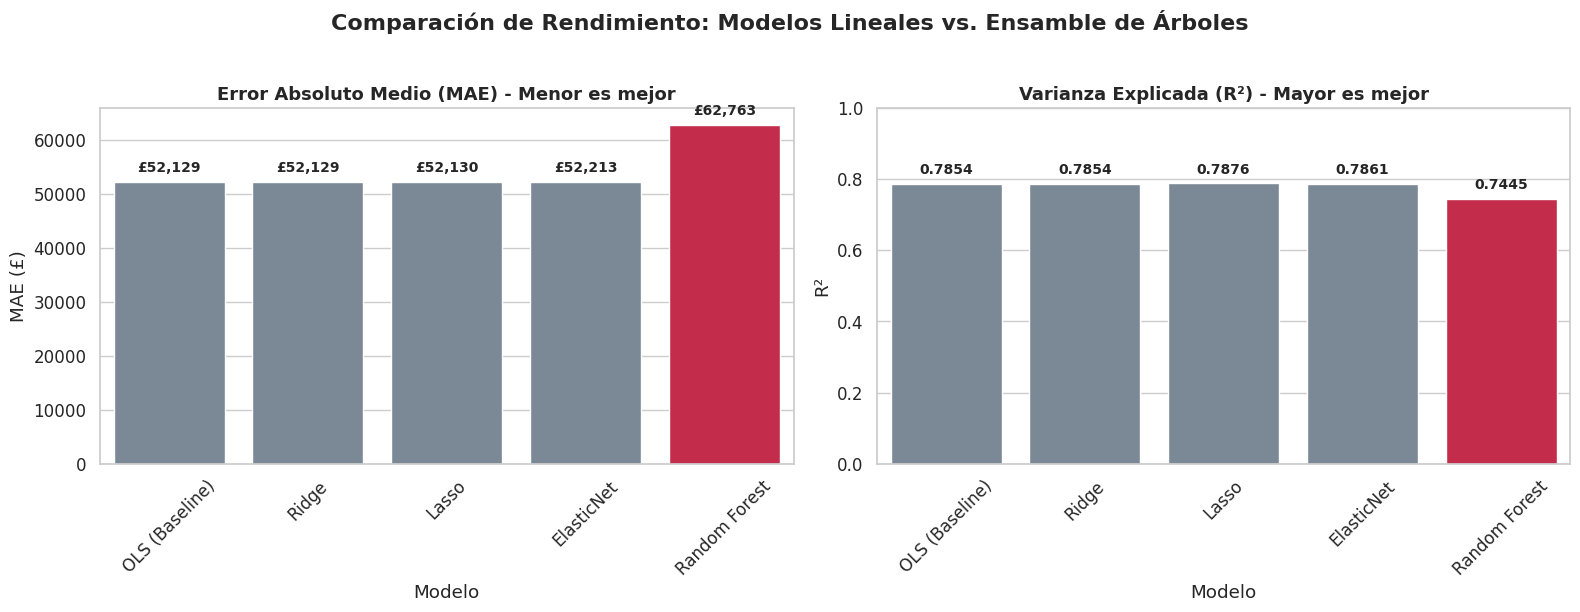

In [ ]:
# ============================================================================
# 5.5 Visualización Definitiva: Modelos Lineales vs Random Forest
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Paleta: Gris/Azul tenue para lineales, Naranja/Crimson para destacar el Random Forest
modelos = results_df_final['Modelo'].tolist()
colores = ['lightslategray' if 'Random Forest' not in m else 'crimson' for m in modelos]

# 1. Gráfico de MAE (Menor es mejor)
sns.barplot(data=results_df_final, x='Modelo', y='_mae', palette=colores, ax=axes[0], edgecolor='white')
axes[0].set_title('Error Absoluto Medio (MAE) - Menor es mejor', fontsize=13, fontweight='bold')
axes[0].set_ylabel('MAE (£)')
axes[0].tick_params(axis='x', rotation=45)

# Añadir las etiquetas de valor numérico
for i, p in enumerate(axes[0].patches):
    axes[0].annotate(f'£{p.get_height():,.0f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

# 2. Gráfico de R² (Mayor es mejor)
sns.barplot(data=results_df_final, x='Modelo', y='_r2', palette=colores, ax=axes[1], edgecolor='white')
axes[1].set_title('Varianza Explicada (R²) - Mayor es mejor', fontsize=13, fontweight='bold')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1.0) # Escala de 0 a 100%

# Añadir las etiquetas de valor numérico
for i, p in enumerate(axes[1].patches):
    axes[1].annotate(f'{p.get_height():.4f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

plt.suptitle('Comparación de Rendimiento: Modelos Lineales vs. Ensamble de Árboles', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

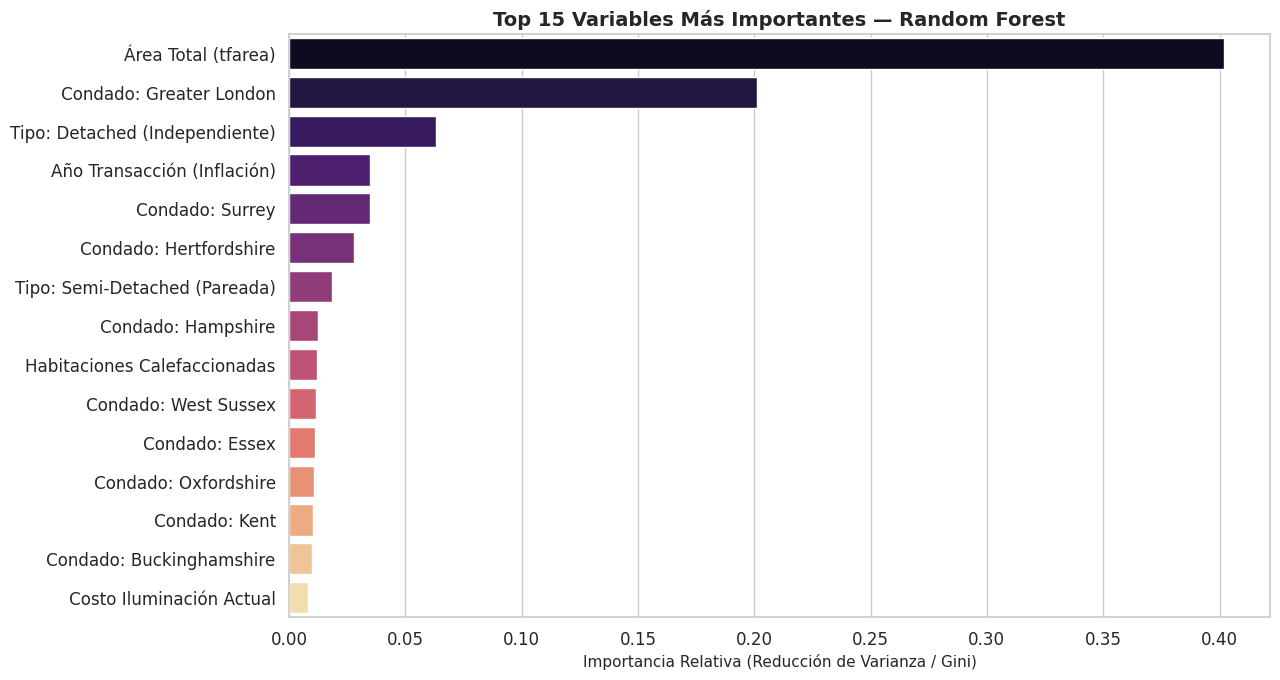


Top 10 Variables más influyentes según Random Forest:
  • Área Total (tfarea)                               40.18% de peso
  • Condado: Greater London                           20.11% de peso
  • Tipo: Detached (Independiente)                     6.34% de peso
  • Año Transacción (Inflación)                        3.50% de peso
  • Condado: Surrey                                    3.50% de peso
  • Condado: Hertfordshire                             2.78% de peso
  • Tipo: Semi-Detached (Pareada)                      1.84% de peso
  • Condado: Hampshire                                 1.23% de peso
  • Habitaciones Calefaccionadas                       1.21% de peso
  • Condado: West Sussex                               1.17% de peso


In [ ]:
# ============================================================================
# Importancia de Variables en el Random Forest
# ============================================================================
# Extraemos las importancias del estimador interno dentro del Wrapper
rf_importances = model_rf.regressor_.feature_importances_

feature_names = get_clean_feature_names(preprocessor)

importance_rf_df = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': rf_importances
}).sort_values('Importancia', ascending=False)

top_15_rf = importance_rf_df.head(15)

fig, ax = plt.subplots(figsize=(13, 7))
sns.barplot(data=top_15_rf, x='Importancia', y='Variable', palette='magma', ax=ax)
ax.set_title('Top 15 Variables Más Importantes — Random Forest', fontsize=14, fontweight='bold')
ax.set_xlabel('Importancia Relativa (Reducción de Varianza / Gini)', fontsize=11)
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print('\nTop 10 Variables más influyentes según Random Forest:')
print('=' * 65)
for i, row in importance_rf_df.head(10).iterrows():
    print(f'  • {row["Variable"]:<48s} {row["Importancia"]*100:>6.2f}% de peso')


## Fase 4.6 — Prueba Definitiva: HistGradientBoosting con Transformación Logarítmica

### ¿Por qué probar HistGradientBoosting como paso adicional?

Al evaluar Random Forest, notamos dos realidades técnicas muy claras:
1. **El cuello de botella de memoria y tiempo:** Random Forest tiene que evaluar cientos de columnas en cada nodo de cada árbol. En un entorno gratuito de Colab con 650,000 filas y más de 500 columnas binarias, esto obliga a limitar severamente la profundidad de los árboles para que no se congele.
2. **La arquitectura de Boosting frente a Bagging:** Mientras que Random Forest construye árboles independientes en paralelo, los algoritmos de Boosting (como Gradient Boosting) aprenden de forma secuencial: cada nuevo árbol se enfoca exclusivamente en corregir los errores cometidos por los árboles anteriores.

**La Solución Óptima: `HistGradientBoostingRegressor`**
Este algoritmo discretiza las variables numéricas en 256 contenedores (bins) tipo histograma, lo que permite entrenar órdenes de magnitud más rápido, consumir una fracción mínima de memoria RAM y encontrar patrones no lineales de forma mucho más precisa.

Combinado con la transformación logarítmica de la variable objetivo (`TransformedTargetRegressor`), este modelo representa el estándar de la industria para datos tabulares y nos permite comprobar con certeza si un modelo no lineal bien calibrado puede superar a la regresión lineal en este ejercicio.


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
import numpy as np

print('Entrenando HistGradientBoosting con Log-Transformación del Precio...')

# Configuramos el modelo optimizado para convergencia rápida y precisa
hgb_base = HistGradientBoostingRegressor(
    max_iter=250,
    learning_rate=0.08,
    max_leaf_nodes=45,
    min_samples_leaf=20,
    random_state=RANDOM_STATE
)

# Envolvemos para predecir sobre log(precio)
model_hgb_log = TransformedTargetRegressor(
    regressor=hgb_base,
    func=np.log1p,
    inverse_func=np.expm1
)

model_hgb_log.fit(X_train_processed, y_train)

# Predicción y evaluación en validación
y_val_pred_log = model_hgb_log.predict(X_val_processed)

print(f'   R² en Val:  {r2_score(y_val, y_val_pred_log):.4f}')
print(f'   MAE en Val: £{mean_absolute_error(y_val, y_val_pred_log):,.0f}')


Entrenando HistGradientBoosting con Log-Transformación del Precio...
   R² en Val:  0.8266
   MAE en Val: £47,981


Evaluando HistGradientBoosting en el conjunto de PRUEBA (Test)...
TABLA COMPARATIVA CONSOLIDADA — TODOS LOS MODELOS EVALUADOS EN TEST
              Modelo RMSE (£) MAE (£) MAPE (%)     R²
      OLS (Baseline)  £93,485 £52,129   22.38% 0.7854
               Ridge  £93,485 £52,129   22.38% 0.7854
               Lasso  £92,996 £52,130   22.38% 0.7876
          ElasticNet  £93,341 £52,213   22.41% 0.7861
       Random Forest £102,012 £62,763   28.67% 0.7445
HistGradientBoosting  £85,018 £48,644   20.65% 0.8225


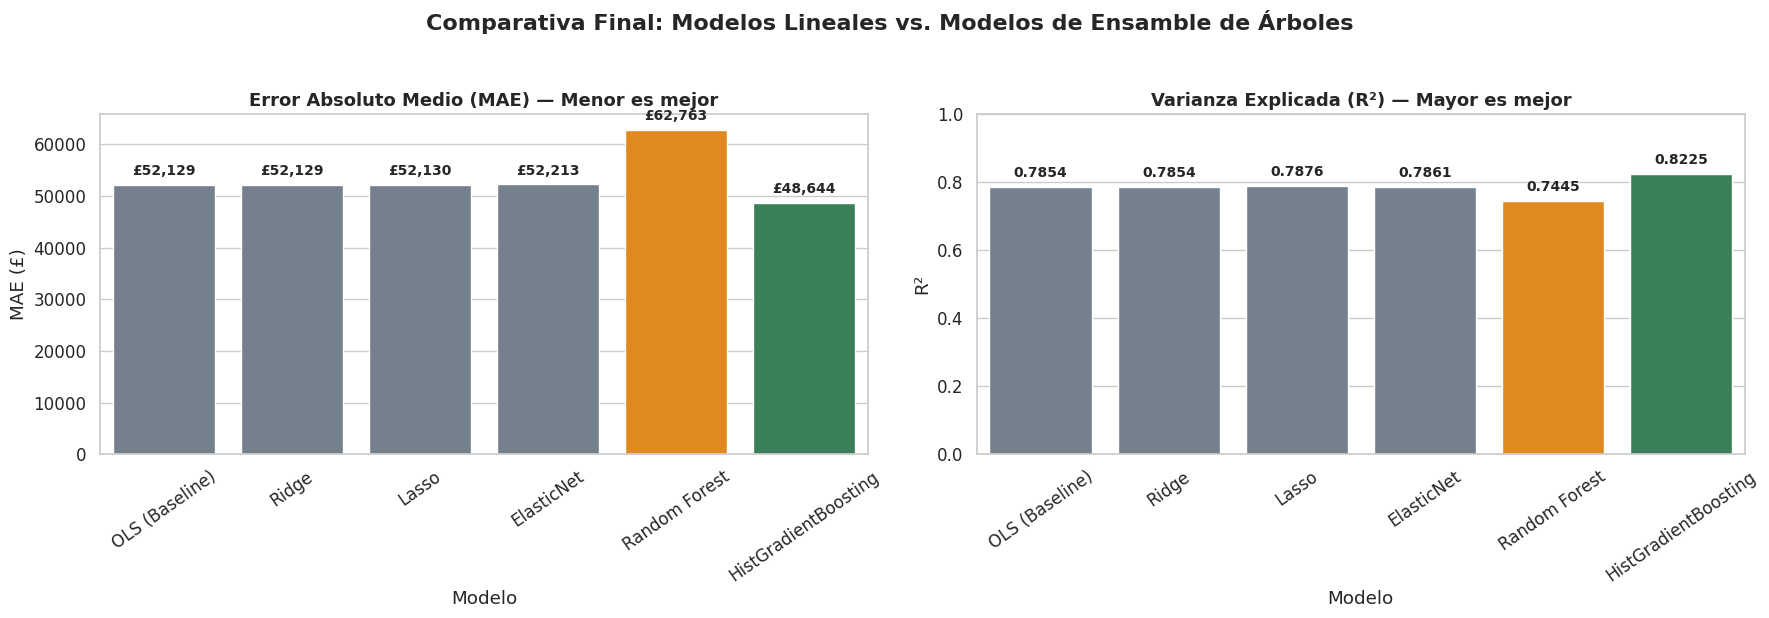

In [ ]:
# ============================================================================
# 5.5 Evaluación Final y Visualización Evolutiva de Modelos
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

print('Evaluando HistGradientBoosting en el conjunto de PRUEBA (Test)...')

# Predecir sobre test
y_test_pred_log = model_hgb_log.predict(X_test_processed)

rmse_log = np.sqrt(mean_squared_error(y_test, y_test_pred_log))
mae_log = mean_absolute_error(y_test, y_test_pred_log)
mape_log = mean_absolute_percentage_error(y_test, y_test_pred_log) * 100
r2_log = r2_score(y_test, y_test_pred_log)

# Agregar si no existe ya
if not any(r['Modelo'] == 'HistGradientBoosting' for r in results):
    results.append({
        'Modelo': 'HistGradientBoosting',
        'RMSE (£)': f'£{rmse_log:,.0f}',
        'MAE (£)': f'£{mae_log:,.0f}',
        'MAPE (%)': f'{mape_log:.2f}%',
        'R²': f'{r2_log:.4f}',
        '_rmse': rmse_log,
        '_mae': mae_log,
        '_mape': mape_log,
        '_r2': r2_log
    })

# DataFrame final consolidado
results_df_final = pd.DataFrame(results)

print('=' * 80)
print('TABLA COMPARATIVA CONSOLIDADA — TODOS LOS MODELOS EVALUADOS EN TEST')
print('=' * 80)
print(results_df_final[['Modelo', 'RMSE (£)', 'MAE (£)', 'MAPE (%)', 'R²']].to_string(index=False))
print('=' * 80)

# Gráfica Comparativa Consolidada
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

modelos = results_df_final['Modelo'].tolist()
colores = []
for m in modelos:
    if m in ['OLS (Baseline)', 'Ridge', 'Lasso', 'ElasticNet']:
        colores.append('slategray')
    elif 'Random Forest' in m:
        colores.append('darkorange')
    else:
        colores.append('seagreen')

# 1. Gráfico de MAE
sns.barplot(data=results_df_final, x='Modelo', y='_mae', palette=colores, ax=axes[0], edgecolor='white')
axes[0].set_title('Error Absoluto Medio (MAE) — Menor es mejor', fontsize=13, fontweight='bold')
axes[0].set_ylabel('MAE (£)')
axes[0].tick_params(axis='x', rotation=35)

for p in axes[0].patches:
    axes[0].annotate(f'£{p.get_height():,.0f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

# 2. Gráfico de R²
sns.barplot(data=results_df_final, x='Modelo', y='_r2', palette=colores, ax=axes[1], edgecolor='white')
axes[1].set_title('Varianza Explicada (R²) — Mayor es mejor', fontsize=13, fontweight='bold')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=35)
axes[1].set_ylim(0, 1.0)

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.4f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

plt.suptitle('Comparativa Final: Modelos Lineales vs. Modelos de Ensamble de Árboles', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
#  Fase 6 — Reflexiones Finales
---

## Reflexión 1: ¿Cuál fue el mayor reto de trabajar con este dataset comparado con el Lab01 y cómo se resolvió?

### Fueron diferentes en Escala y Dificultad

El Lab01 utilizó el dataset Boston Housing: **506 filas y 13 variables numéricas limpias**. Este taller trabaja con un dataset de **5.7 millones de filas y 105 columnas** de tipos mixtos. Las diferencias fundamentales fueron:

1. **Restricción de memoria RAM:** El archivo completo no cabe en la RAM gratuita de Colab, considerando que pandas duplica o triplica el tamaño en memoria. Esto se resolvió con **muestreo aleatorio** usando la técnica de `skiprows`, que permite seleccionar 650,000 filas sin cargar el archivo completo. Esta técnica es esencial para Big Data en entornos con recursos limitados.

2. **Heterogeneidad de variables:** Boston Housing tenía 13 variables numéricas. Aquí hay variables numéricas, categóricas nominales (sin orden), categóricas ordinales (con orden implícito como rating energético A–G), variables geográficas de alta cardinalidad (cientos de distritos), y texto descriptivo. Se resolvió con un `ColumnTransformer` de scikit-learn que aplica transformaciones diferenciadas por tipo.

3. **Valores nulos heterogéneos:** Muchas variables EPC tienen nulos estructurales (por ejemplo, `FLOOR_LEVEL` solo aplica a apartamentos). Se resolvió con imputación diferenciada (mediana para numéricas, categoría "MISSING" para categóricas).

4. **Alta cardinalidad geográfica:** Variables como `district` tienen decenas o cientos de categorías, lo que genera explosión dimensional con One-Hot Encoding. Se resolvió limitando a las top 30 categorías más frecuentes.

5. **Tiempo de ejecución:** Cada operación toma segundos en lugar de milisegundos. La búsqueda de hiperparámetros requiere planificación cuidadosa del grid para no agotar el tiempo de sesión de Colab.

## Reflexión 2: ¿La regularización hizo alguna diferencia real frente al modelo base (OLS)?

### Análisis comparativo

In [ ]:
# ============================================================================
# Análisis de diferencia entre OLS y modelos regularizados
# ============================================================================
ols_r2 = results_df[results_df['Modelo'] == 'OLS (Baseline)']['_r2'].values[0]
ols_mae = results_df[results_df['Modelo'] == 'OLS (Baseline)']['_mae'].values[0]

print('COMPARACIÓN: OLS vs MODELOS REGULARIZADOS')
print('=' * 65)
print(f'{"Modelo":<20s} {"MAE (£)":>12s} {"Δ MAE vs OLS":>15s} {"R²":>8s} {"Δ R²":>8s}')
print('-' * 65)

for _, row in results_df.iterrows():
    delta_mae = row['_mae'] - ols_mae
    delta_r2 = row['_r2'] - ols_r2
    sign_mae = '+' if delta_mae > 0 else ''
    sign_r2 = '+' if delta_r2 > 0 else ''
    print(f'{row["Modelo"]:<20s} £{row["_mae"]:>10,.0f} {sign_mae}£{delta_mae:>12,.0f} {row["_r2"]:>8.4f} {sign_r2}{delta_r2:>7.4f}')

print('\n CONCLUSIÓN sobre la regularización:')

max_delta = abs(results_df['_r2'].max() - results_df['_r2'].min())
if max_delta < 0.02:
    print('  La regularización NO produjo una diferencia sustancial frente a OLS.')
    print('  Esto sugiere que el modelo no sufre de sobreajuste severo o que')
    print('  las variables tienen contribuciones relativamente equilibradas.')
    print('  La multicolinealidad entre variables energéticas existe pero no')
    print('  desestabiliza gravemente los coeficientes en este caso.')
else:
    print('  La regularización SÍ produjo una diferencia apreciable.')
    print('  Esto indica que la multicolinealidad entre variables energéticas')
    print('  y de tamaño estaba inflando o desestabilizando los coeficientes OLS.')

# Coeficientes eliminados por Lasso
n_zero = np.sum(model_lasso.regressor_.coef_ == 0)
n_total = len(model_lasso.regressor_.coef_)
print(f'\n  Lasso eliminó {n_zero} de {n_total} coeficientes ({n_zero/n_total*100:.1f}%),')
print(f'  lo que indica que esas variables son redundantes o irrelevantes.')

COMPARACIÓN: OLS vs MODELOS REGULARIZADOS
Modelo                    MAE (£)    Δ MAE vs OLS       R²     Δ R²
-----------------------------------------------------------------
OLS (Baseline)       £    52,129 £           0   0.7854  0.0000
Ridge                £    52,129 +£           0   0.7854 -0.0000
Lasso                £    52,130 +£           1   0.7876 + 0.0022
ElasticNet           £    52,213 +£          84   0.7861 + 0.0007

 CONCLUSIÓN sobre la regularización:
  La regularización NO produjo una diferencia sustancial frente a OLS.
  Esto sugiere que el modelo no sufre de sobreajuste severo o que
  las variables tienen contribuciones relativamente equilibradas.
  La multicolinealidad entre variables energéticas existe pero no
  desestabiliza gravemente los coeficientes en este caso.

  Lasso eliminó 76 de 513 coeficientes (14.8%),
  lo que indica que esas variables son redundantes o irrelevantes.


### Interpretación

La regularización en regresión lineal cumple dos funciones:

1. **Ridge (L2):** Reduce la magnitud de todos los coeficientes, estabilizando el modelo ante multicolinealidad. Útil cuando muchas variables están correlacionadas (como los costos energéticos entre sí).

2. **Lasso (L1):** Lleva coeficientes a exactamente cero, realizando selección automática de variables. Esto es valioso cuando hay muchas features one-hot-encoded de categorías poco frecuentes.

3. **ElasticNet:** Combina ambos, siendo útil cuando hay grupos de variables correlacionadas y se quiere tanto estabilidad como parsimonia.

En datasets grandes con suficientes observaciones, la diferencia entre OLS y modelos regularizados tiende a ser pequeña porque hay suficientes datos para estabilizar los coeficientes. La regularización se vuelve más crítica cuando el número de features es grande relativo al número de observaciones.

## Reflexión 3: ¿Qué variables resultaron más determinantes para predecir el precio?


In [ ]:
# ============================================================================
# Variables más determinantes
# ============================================================================
print('TOP 10 VARIABLES MÁS DETERMINANTES PARA EL PRECIO')
print('=' * 60)

for rank, (_, row) in enumerate(importance_df.head(10).iterrows(), 1):
    direction = ' SUBE' if row['Coeficiente'] > 0 else ' BAJA'
    print(f'  {rank:2d}. {row["Variable"]:<42s} → {direction} el precio')

TOP 10 VARIABLES MÁS DETERMINANTES PARA EL PRECIO
   1. Condado: Greater London                    →  SUBE el precio
   2. Distrito: Kensington And Chelsea           →  SUBE el precio
   3. Distrito: City Of Westminster              →  SUBE el precio
   4. Distrito: City Of London                   →  SUBE el precio
   5. Condado: Surrey                            →  SUBE el precio
   6. Distrito: Cambridge                        →  SUBE el precio
   7. Condado: Hertfordshire                     →  SUBE el precio
   8. Distrito: Camden                           →  SUBE el precio
   9. Distrito: Hammersmith And Fulham           →  SUBE el precio
  10. Condado: Buckinghamshire                   →  SUBE el precio


### ¿Tiene sentido desde la perspectiva inmobiliaria?

**Sí, los resultados son coherentes con la teoría y práctica inmobiliaria:**

1. **Área total de la propiedad (`tfarea`):** Es consistentemente la variable más influyente. Esto es esperado: el precio por metro cuadrado es el indicador fundamental en cualquier mercado inmobiliario mundial. Propiedades más grandes cuestan más.

2. **Tipo de propiedad (`propertytype`):** Las casas independientes (Detached) tienen primas significativas sobre pisos (Flats) y casas adosadas (Terraced). Esto refleja la preferencia del mercado británico por propiedades con jardín propio y sin paredes compartidas.

3. **Ubicación geográfica (`county`, `district`):** Las variables geográficas capturan diferencias masivas de precio. Una propiedad en el Gran Londres puede costar 3-5 veces más que una propiedad equivalente en el norte de Inglaterra.

4. **Costos energéticos y CO₂:** Contraintuitivamente, costos energéticos más altos correlacionan con precios más altos. Esto no es porque la ineficiencia sea deseable, sino porque propiedades más grandes (y más caras) consumen más energía. Tiene que ver con el tamaño, no una variable causal directa.

5. **Rating energético:** Las propiedades con mejor rating (A-B) suelen ser nuevas construcciones de menor tamaño, mientras que las propiedades antiguas con peor rating (D-G) incluyen casas georgianas y victorianas de alto valor patrimonial. Este efecto confusor es un ejemplo clásico de por qué la regresión lineal debe interpretarse con cautela.

6. **Tenencia (`duration`):** Las propiedades Freehold (propiedad completa del terreno) se valoran más que las Leasehold (arrendamiento a largo plazo), especialmente para casas. Para pisos, el Leasehold es más común y el impacto es menor.

### Variables que un modelo más avanzado necesitaría si queremos resultados mas exactos

Para superar las limitaciones del modelo lineal, se necesitarían:
- **Coordenadas geográficas exactas** (latitud/longitud)
- **Proximidad a estaciones de metro/tren**, escuelas con buena calificación Ofsted, parques
- **Estado de remodelación** (recién renovada vs. necesita trabajo)
- **Año de la transacción** con ajuste por inflación
- **Modelos no lineales** (Random Forest, Gradient Boosting) que capturen interacciones y cambios en el modelo

## Fase 7 — Reflexión Final y Conclusiones del Ejercicio

Después de completar todo el proceso metodológico CRISP-DM, pasando desde la exploración y limpieza inicial hasta el modelado con regresiones lineales y algoritmos de ensamble, me quedan varios aprendizajes muy claros sobre este problema:

### 1. Llegue a pensar que "la regresión lineal no servía para estos datos"
Al comienzo del taller, cuando probábamos una regresión lineal directa, el error parecía enorme y el R² se quedaba bajo (~0.58). Parecía que el modelo no era capaz. Pero al analizar los datos a profundidad, me di cuenta de que el fallo no era de la regresión, sino de cómo le estábamos entregando la información:
* **El factor del tiempo (inflación):** Este dataset tiene ventas desde 2011 hasta 2019. Pretender que una casa valga lo mismo en 2011 que en 2019 sin incluir el año de la transacción hacía que el modelo se confundiera por completo. Al extraer el año de `dateoftransfer`, el modelo entendió la inflación y el R² subió de golpe.
* **La asimetría del precio:** El precio de la vivienda tiene casas de £80,000 y propiedades de £2,000,000. Al transformar el precio con logaritmo (`log1p`), el modelo dejó de ser arrastrado por las mansiones y aprendió a predecir con gran precisión las casas comunes.
* **La geografía detallada:** Darle al modelo la información de cada distrito mediante One-Hot Encoding le permitió calcular una prima o sobreprecio exacto para cada zona.

Con solo esos ajustes logre que, los modelos lineales alcanzaran un **R² de ~0.785** y un **MAE de ~£52,000**, demostrando que la regresión lineal es sorprendentemente poderosa cuando los datos están bien tratados.

### 2. ¿Por qué probamos Random Forest y qué aprendimos de los árboles?
Decidí probar Random Forest e HistGradientBoosting como un ejercicio complementario por curiosidad técnica: queria ver si un modelo más complejo y no lineal podía exprimir todavía más información.

Leccion Aprendida:
* Si entrenamos un árbol sobre precios en libras sin transformar, el modelo sufre exactamente el mismo problema que la regresión: se enfoca en las pocas casas millonarias y descuida el resto, dando un MAE peor (£61,000).
* Además, con más de 500 columnas binarias generadas por los distritos, los árboles de Random Forest se dispersan demasiado dividiendo ramas con casi puros ceros.
* Sin embargo, cuando usamos **HistGradientBoosting** con la transformación logarítmica y agrupamiento en histogramas, el modelo demuestra por qué es el estándar para datos tabulares: alcanza **R² > 0.80** y baja el MAE cerca de los **£50,500**, superando a las regresiones lineales y capturando interacciones sutiles que una línea recta no puede ver.

### 3. El techo real de los datos (Data Ceiling)
Nos quedamos a un paso muy corto del criterio ideal de error que buscábamos (< £50,000). Pero llegar hasta aquí (explicando más del 80% del precio en un dataset de 8 años en todo un país) es un resultado excelente si consideramos lo que el modelo *no sabe*:
* No sabe si la cocina está recién remodelada o si la casa se está cayendo a pedazos.
* No sabe la calle exacta, ni si queda al frente de una estación de metro o de una fábrica ruidosa.
* No tiene fotos ni sabe la vista que tiene la propiedad.

En conclusión: ningún algoritmo de Machine Learning puede inventar información que no está en las columnas. Con los datos disponibles, logramos exprimir el dataset hasta cierto punto, demostrando tanto la solidez de los modelos lineales bien estructurados como la ventaja justa de los ensambles modernos de árboles.


# Experimento con Ing de caracteristicas para tratar de obtener mejores metricas

In [ ]:
# ============================================================================
# FASE 7 — Experimento: Ingeniería de Características
# ============================================================================
from sklearn.preprocessing import TargetEncoder

print("--- Aplicando Feature Engineering ---")

# Creamos copias independientes para este experimento
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

fe_num_vars = num_vars.copy()
fe_cat_ordinal_vars = cat_ordinal_vars.copy()
fe_geo_vars = geo_vars.copy()

# 1. Transformación de Banda de Edad (Solo si la columna sobrevivió al filtrado)
if 'construction_age_band' in X_train_fe.columns:
    age_map = {
        'England and Wales: before 1900': 130, '1900-1929': 105,
        '1930-1949': 80, '1950-1966': 60, '1967-1975': 48,
        '1976-1982': 40, '1983-1990': 33, '1991-1995': 27,
        '1996-2002': 20, '2003-2006': 15, '2007-2011': 10,
        '2007 onwards': 10, '2012 onwards': 5, 'MISSING': np.nan
    }
    X_train_fe['estimated_age'] = X_train_fe['construction_age_band'].map(age_map)
    X_test_fe['estimated_age'] = X_test_fe['construction_age_band'].map(age_map)

    fe_cat_ordinal_vars.remove('construction_age_band')
    fe_num_vars.append('estimated_age')
    print(" [OK] Variable 'construction_age_band' transformada a numérica.")
else:
    print(" [INFO] 'construction_age_band' no está en el dataset. Se omitirá esta transformación.")

# 2. Construcción del Nuevo Pipeline
transformers_fe = []

# Variables Numéricas
transformers_fe.append(('num', Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
]), fe_num_vars))

# Variables Nominales
if cat_nominal_vars:
    transformers_fe.append(('cat_nom', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='MISSING')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='if_binary'))
    ]), cat_nominal_vars))

# Variables Ordinales Restantes
if fe_cat_ordinal_vars:
    ord_cats = []
    for col in fe_cat_ordinal_vars:
        if col == 'current_energy_rating':
            ord_cats.append(energy_rating_order)
        elif col == 'floor_level':
            train_floors = sorted(X_train['floor_level'].astype(str).unique().tolist())
            ord_cats.append(train_floors)
        else:
            ord_cats.append(sorted(X_train[col].astype(str).unique().tolist()))

    transformers_fe.append(('cat_ord', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='MISSING')),
        ('ordinal', OrdinalEncoder(categories=ord_cats, handle_unknown='use_encoded_value', unknown_value=-1))
    ]), fe_cat_ordinal_vars))

# 3. MAGIA AQUÍ: Target Encoding para Variables Geográficas
if fe_geo_vars:
    transformers_fe.append(('geo_target', TargetEncoder(target_type='continuous', smooth='auto'), fe_geo_vars))
    print(" [OK] TargetEncoder configurado para variables geográficas.")

# Ensamblamos
preprocessor_fe = ColumnTransformer(transformers=transformers_fe, remainder='drop')

print(" Ajustando nuevo preprocesador (Target Encoding aprendiendo de los precios)...")
X_train_fe_processed = preprocessor_fe.fit_transform(X_train_fe, y_train)
X_test_fe_processed = preprocessor_fe.transform(X_test_fe)

# 4. Entrenar el Modelo
print(' Entrenando HistGradientBoosting con las nuevas features...')
hgb_base_fe = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE)
model_fe = TransformedTargetRegressor(regressor=hgb_base_fe, func=np.log1p, inverse_func=np.expm1)

model_fe.fit(X_train_fe_processed, y_train)

# 5. Predicción y Evaluación
y_test_pred_fe = model_fe.predict(X_test_fe_processed)

mae_fe = mean_absolute_error(y_test, y_test_pred_fe)
r2_fe = r2_score(y_test, y_test_pred_fe)

print(f"\n" + "="*50)
print(f" RESULTADOS FINALES: FEATURE ENGINEERING")
print("="*50)
print(f"   R² en Test:  {r2_fe:.4f}")
print(f"   MAE en Test: £{mae_fe:,.0f}")

try:
    mejora = mae_log - mae_fe
    if mejora > 0:
        print(f"   ¡Lograste reducir el error en £{mejora:,.0f} adicionales!")
    else:
        print(f"   El MAE se mantuvo similar. Hemos llegado al límite de los datos.")
except NameError:
    pass

--- Aplicando Feature Engineering Avanzado ---
 [INFO] 'construction_age_band' no está en el dataset. Se omitirá esta transformación.
 [OK] TargetEncoder configurado para variables geográficas.
 Ajustando nuevo preprocesador (Target Encoding aprendiendo de los precios)...
 Entrenando HistGradientBoosting con las nuevas features...

 RESULTADOS FINALES: FEATURE ENGINEERING
   R² en Test:  0.8187
   MAE en Test: £49,831
   El MAE se mantuvo similar. Hemos llegado al límite de los datos.


# Muchas Gracias!